# Experiment 03: what actually goes wrong at low discount factors? (diagnostics + mechanism tests, 3 seeds)

**Experiment ID:** `03_diagnostics` - part of [dqn-lunarlander-experiments](https://github.com/mjsafy/dqn-lunarlander-experiments).
Raw outputs (checkpoints, weight snapshots) live on Google Drive in `dqn_lunar/03_diagnostics/`; figures, summary CSVs, per-run result files and videos are copied to `results/03_diagnostics/` in the repo.

**Background.** Experiment 01 showed *that* DQN with `gamma <= 0.95` fails on LunarLander and that every unsolved learning curve rises and then falls. It could not show *why*, because only returns and episode lengths were recorded.
Its write-up lists several candidate explanations. This notebook measures what the agents actually do and tests each candidate explanation, with 3 seeds and pre-registered decision rules.

**What is new compared with Experiment 01**

1. **Agent:** a plain-NumPy DQN with the same architecture and hyper-parameters (8-64-64-4 ReLU, Adam 1e-3, soft target `tau = 1e-3`, batch 64, one update per 4 env steps, replay 100k, per-episode epsilon decay 0.995). TensorFlow is not used. It is ~5x faster in profiling (measured in a separate session, not in this notebook) and is checked against the TF results of Experiment 01 in Section 5 before it is trusted at low gamma.
2. **Measurements:** per-episode termination reason, final state, action frequencies, altitude, loss, Q statistics, replay-buffer terminal fraction; a greedy evaluation every 50 episodes; weight snapshots every 50 episodes (for videos).
3. **Stopping:** no fixed episode budget and no "solved" stop. A run stops when its training return has stopped improving beyond noise (Section 2), so solved runs are observed after solving and failing runs are observed long enough after their peak.
4. **Seeds and evaluation:** 3 seeds per setting, 20 held-out greedy episodes every 50 episodes, 100 at the end.
5. **Interventions:** four arms that each change one thing relative to the baseline, to test causes rather than only describe symptoms.
6. **Videos:** greedy rollouts of saved policies, for people who do not read tables.

**Resumability.** Every run writes a two-slot checkpoint (networks, Adam state, replay buffer, RNG states, all logs) every 25 episodes and a finished-marker (`.npz`) at the end. If the Colab session dies, run the same cells again: finished runs are skipped and unfinished runs continue from their last checkpoint. Episodes are seeded from `(seed, episode)`, so a resumed run is meant to be identical to an uninterrupted one (checked in the smoke test).

**Reading guide.** Statements labelled *measured* come from this notebook's output. Statements labelled *reasoning* are explanations that the data may or may not support.

## 0. Pre-registered hypotheses, decision rules and statistics

*This section is written before any run. If anything here is changed after seeing results, record it in the "Deviations" cell at the end.*

**Design facts that shape the statistics.** There are 3 seeds per (arm, gamma). Runs with the same seed share the initial network weights and the sequence of training-episode initial conditions across arms and gammas, so arm-vs-baseline comparisons are **paired by (gamma, seed)**. Three seeds cannot support a per-gamma significance test; tests below pool runs, treat each run as one unit, and are therefore **exploratory about gamma-specific claims** and confirmatory only about the pooled statement.

**Primary outcome measures** (all use the 100-episode final greedy evaluation on held-out initial conditions, except where stated):
`final_eval_mean` = mean return; `time_limit_share` = share of evaluation episodes that end by the 1000-step limit (airborne or resting on the ground).

**Selection bias warning.** "A curve rises, then falls" is partly an artefact of looking at a noisy series: the maximum of a noisy curve is higher than what follows even if nothing changed. Therefore the peak location is chosen from the **training** returns, but the decline is measured on the **independent greedy evaluations** (different episodes, fixed held-out initial conditions), never on the series that chose the peak.

| ID | Claim (from the Experiment 01 write-up) | Evidence | Decision rule |
|---|---|---|---|
| **H1** | `gamma >= 0.99` solves the task, `gamma <= 0.95` does not (replication with a new agent and 3 seeds) | `solved_at` per run | Replicated if 3/3 seeds solve at 0.995 and 0.99 and 0/3 solve at each of the six lower values. Otherwise report counts. |
| **H2** | Failing runs *hover*: final greedy episodes end at the time limit, not by landing or crashing | `final_outcome`, altitude, engine use | Supported if, for each gamma in {0.95, 0.9, 0.895, 0.89}, at least 2 of 3 seeds have `time_limit_share >= 0.5`, and the median share of solved runs is `< 0.1`. The airborne/ground split is reported, not tested. |
| **H3** | The post-peak decline is a real policy degradation | greedy evaluation around the training-return peak vs the last 3 evaluations, unsolved baseline runs | One-sided exact sign-flip test on the mean decline across unsolved runs (unit = run), Holm-corrected; also the effect must exceed the typical seed spread. |
| **H4** | Epsilon decay unmasks a bad greedy policy (instead of the policy degrading) | gap = training mean - greedy mean over time | Decided from H3 and the gap curves: if H3 is supported, masking is at most a contributor; if H3 is not supported while training return still falls, the data fit masking. No separate p-value (the training decline is selection-biased). |
| **H5** | Solved runs also collapse if training continues (survivor effect) | greedy evaluation just after solving vs last 3 evaluations, solved baseline runs | One-sided exact sign-flip test, unit = run, Holm-corrected, effect must exceed seed spread. |
| **H6** | Replay-buffer flooding by long episodes causes the decline | arm `big_buffer` (1,000,000) vs baseline; buffer terminal fraction logged | One-sided paired test on `final_eval_mean` at gamma in {0.95, 0.9, 0.8} (9 pairs), Holm-corrected, effect > seed spread. The terminal-fraction curves are descriptive. |
| **H7** | The environment's shaping reward is inconsistent with `gamma < 1` and drives the failure | arm `shaping_fix` (`r - (1-gamma) * Phi(s')` on non-terminal steps; training signal only, returns are always reported with the original reward) | Same test as H6. gamma = 0.99 is reported as a do-no-harm control. |
| **H8** | Treating the time limit as non-terminal removes any signal that hovering ends | arm `trunc_terminal` | Two-sided paired test on `time_limit_share` at gamma in {0.95, 0.9, 0.8}, Holm-corrected, effect > seed spread. |
| **H9** | Generic DQN instability (squared loss on rewards of order 100) | arm `huber` (Huber loss, delta = 1) vs baseline; Q statistics logged | Same test as H6. Q growth is descriptive. |
| **H10** | The effective horizon is far shorter than the flight | landing-episode lengths of solved runs vs `gamma^length` | Descriptive table only (arithmetic, no test). |

**Holm family:** H3, H5, H6, H7, H8, H9 (six tests, family-wise alpha 0.05). **Seed spread** for a metric = median over baseline gammas of the standard deviation across the 3 seeds; a difference smaller than that is not reported as an effect even if p is small.
**What these tests cannot do:** with 12 or fewer pairs from only 3-4 gammas, a "not supported" verdict means *no detectable effect at this sample size*, not *no effect*. Units from the same gamma are not fully independent, so p-values are optimistic; treat them as ranking evidence.

**Stopping rule (applies to every run).** Every 50 episodes (once 100 episodes exist) compute `m` = mean training return of the last 100 episodes and `se` = its naive standard error (std/10). If `m > best + 2*se`, then `best = m` and the "last improvement" episode is updated. The run stops when at least `min_episodes = 500` episodes are done **and** 300 episodes have passed since the last improvement, or at `max_episodes = 1500`.
*Why this form (reasoning):* it has no fixed score threshold; an improving run keeps going; a run that peaked is followed for at least 300 more episodes, which is the span over which the Experiment 01 declines happened, so the decline can be measured; a solved run is followed after solving. *Known weaknesses:* `se` ignores autocorrelation (it is too small), so a noisy plateau can occasionally reset the counter; the rule uses training returns, which are measured under epsilon-greedy noise. The stop reason and the full check log are saved per run. *Calibration on synthetic curves (simulated outside this notebook, 300 curves each, noise sd 60; the smoke test repeats a version):* flat noisy curves stop at 500-650 episodes (10th-90th percentile); a curve that rises to episode 600 and then falls stops about 300-400 episodes after the peak; a curve rising by 0.15 per episode is mostly not stopped. Real curves are autocorrelated and non-stationary, so this is a sanity check, not a guarantee. Because stopping is data-dependent, runs have different lengths: **compare runs at matched episodes or by post-peak spans, not by the final episode number.**

## 1. Setup

In [ ]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Box2D needs swig to build. No TensorFlow is needed in this notebook.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "swig"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium[box2d]", "imageio",
                    "imageio-ffmpeg", "threadpoolctl"], check=True)

In [ ]:
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")        # headless rendering for the videos
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")                        # one BLAS thread per process (best effort; workers also use threadpoolctl)

import json, time, math, platform, shutil, tempfile, itertools, multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

EXPERIMENT = "03_diagnostics"                 # must match the notebook name, the Drive folder and results/<EXPERIMENT>/ in the repo
REPO_URL = "https://github.com/mjsafy/dqn-lunarlander-experiments"
GITHUB_BLOB = f"{REPO_URL}/blob/main/results/{EXPERIMENT}"
GITHUB_RAW = f"{REPO_URL}/raw/main/results/{EXPERIMENT}"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/dqn_lunar") / EXPERIMENT
    STATUS_DIR = Path("/content/_status")                 # local disk: live progress files (not persistent, not needed)
else:
    def _find_repo_root():
        here = Path.cwd().resolve()
        for p in [here, *here.parents]:
            if (p / ".git").exists():
                return p
        return here
    ROOT = _find_repo_root() / "results" / EXPERIMENT
    STATUS_DIR = Path(tempfile.gettempdir()) / "dqn_status"

RUNS_DIR = ROOT / "runs"            # one small .npz per finished run (committed to the repo)
SNAP_DIR = ROOT / "snapshots"       # weight snapshots for the videos (Drive only)
FIG_DIR = ROOT / "figures"
VIDEO_DIR = ROOT / "videos"
for d in (RUNS_DIR, SNAP_DIR, FIG_DIR, VIDEO_DIR, STATUS_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP1_RUNS_DIR = ROOT.parent / "01_gamma_sweep" / "runs"   # TensorFlow reference results (used only by the validation stage)


def get_code_commit():
    """Commit of the code that produced these results. Local: HEAD of the checkout.
    Colab: latest commit on the remote main branch, so push the notebook BEFORE running it."""
    try:
        if IN_COLAB:
            out = subprocess.run(["git", "ls-remote", REPO_URL, "HEAD"], capture_output=True, text=True,
                                 timeout=30, check=True).stdout
            return out.split()[0]
        return subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, timeout=30,
                              check=True, cwd=ROOT).stdout.strip()
    except Exception as e:
        return f"unknown ({type(e).__name__})"


env_info = {
    "experiment": EXPERIMENT, "code_commit": get_code_commit(), "agent": "numpy-dqn",
    "python": platform.python_version(), "gymnasium": gym.__version__, "numpy": np.__version__,
    "pandas": pd.__version__, "platform": platform.platform(), "cpu_count": os.cpu_count(),
}
(ROOT / "env_info.json").write_text(json.dumps(env_info, indent=2))
print(json.dumps(env_info, indent=2))
print("Results directory:", ROOT.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "experiment": "03_diagnostics",
  "code_commit": "843ed3ece2819a0d1fd2b6fd1947801fdab3d614",
  "agent": "numpy-dqn",
  "python": "3.13.16",
  "gymnasium": "1.3.0",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "cpu_count": 2
}
Results directory: /content/drive/MyDrive/dqn_lunar/03_diagnostics


## 2. Configuration

One dictionary holds every hyper-parameter, and every saved run stores the full configuration it was produced with.
`ARMS` lists the experimental arms; an arm changes only the keys in `overrides`. The baseline arm uses all 8 gammas; the intervention arms use `INTERVENTION_GAMMAS` by default (two failing-regime gammas that hovered in Experiment 01, the best-looking failing gamma, and 0.99 as a do-no-harm control). Set `INTERVENTION_GAMMAS = CONFIG["gammas"]` to run all 8 (roughly 2.7x the intervention cost).

In [ ]:
CONFIG = {
    "env_id": "LunarLander-v3",
    "gammas": [0.995, 0.99, 0.95, 0.9, 0.895, 0.89, 0.85, 0.8],
    "seeds": [0, 1, 2],
    # --- DQN: identical to Experiment 01 ---
    "hidden_units": 64, "lr": 1e-3, "tau": 1e-3,
    "buffer_size": 100_000, "batch_size": 64, "update_every": 4,
    "eps_start": 1.0, "eps_decay": 0.995, "eps_min": 0.01,       # epsilon is decayed once per episode
    # --- switches used by the intervention arms ---
    "loss": "mse",                    # "mse" or "huber"
    "huber_delta": 1.0,
    "shaping_fix": False,             # learn from r - (1-gamma)*Phi(s') on non-terminal steps (returns are still reported with the raw reward)
    "truncation_is_terminal": False,  # False: the 1000-step time limit is NOT a terminal state (as in Experiment 01)
    # --- run length and adaptive stopping (see Section 0) ---
    "max_episodes": 1500, "min_episodes": 500,
    "solve_threshold": 200.0, "solve_window": 100,    # 'solved' is only recorded, it never stops a run
    "stop_check_every": 50, "stop_z": 2.0, "stop_patience": 300,
    # --- evaluation and persistence ---
    "eval_every": 50, "n_eval_episodes": 20, "n_final_eval_episodes": 100,
    "checkpoint_every": 25, "snapshot_every": 50,
}

INTERVENTION_GAMMAS = [0.99, 0.95, 0.9, 0.8]
ARMS = {
    "baseline":       {"overrides": {}, "gammas": CONFIG["gammas"]},
    "shaping_fix":    {"overrides": {"shaping_fix": True}, "gammas": INTERVENTION_GAMMAS},
    "big_buffer":     {"overrides": {"buffer_size": 1_000_000, "checkpoint_every": 100}, "gammas": INTERVENTION_GAMMAS},
    "trunc_terminal": {"overrides": {"truncation_is_terminal": True}, "gammas": INTERVENTION_GAMMAS},
    "huber":          {"overrides": {"loss": "huber"}, "gammas": INTERVENTION_GAMMAS},
    # validation stage only (Section 5): short, fixed length, no early stopping
    "validation":     {"overrides": {"max_episodes": 400, "min_episodes": 10**9}, "gammas": [0.95, 0.9]},
}
INTERVENTION_ARMS = ["shaping_fix", "big_buffer", "trunc_terminal", "huber"]

N_PROCS = max(1, min(2, os.cpu_count() or 1))        # Colab free tier has 2 vCPUs

# Held-out evaluation initial conditions, identical for every run (common random numbers).
EVAL_SEEDS_PERIODIC = [10_000 + i for i in range(CONFIG["n_eval_episodes"])]
EVAL_SEEDS_FINAL = [20_000 + i for i in range(CONFIG["n_final_eval_episodes"])]


def arm_cfg(arm):
    cfg = dict(CONFIG)
    cfg.update(ARMS[arm]["overrides"])
    cfg["arm"] = arm
    return cfg


def run_name(arm, gamma, seed):
    return f"{arm}__gamma{gamma:.3f}_seed{seed}"


def train_env_seed(seed, episode):
    """Initial-condition seed of a training episode. Depends only on (seed, episode): the same across arms and gammas,
    and it makes a resumed run identical to an uninterrupted one."""
    return int(np.random.SeedSequence([int(seed), int(episode)]).generate_state(1)[0] % (2**31 - 1))

## 3. NumPy DQN

Specification (identical to the TensorFlow agent of Experiment 01 except where stated):
`h1 = relu(x W1 + b1)`, `h2 = relu(h1 W2 + b2)`, `q = h2 W3 + b3`; Glorot-uniform weights, zero biases, float32.
Target `y = r + gamma * max_a Q_target(s') * (1 - done)`; loss = mean squared error (or Huber in the `huber` arm). The **time limit is not terminal** unless the arm says so.
Adam in Keras form (`lr_t = lr*sqrt(1-b2^t)/(1-b1^t)`, `eps = 1e-7`); soft target update after every learning step. Acting uses the same arrays, no copying.

In [ ]:
class ReplayBuffer:
    """Circular replay buffer. `dones` is the bootstrap mask used in the target; `true_term` records env termination
    (diagnostics only) so the terminal fraction can be logged even when the time limit is treated as terminal."""

    def __init__(self, capacity, state_dim, rng):
        self.capacity, self.rng = capacity, rng
        self.states = np.zeros((capacity, state_dim), np.float32)
        self.actions = np.zeros(capacity, np.int64)
        self.rewards = np.zeros(capacity, np.float32)
        self.next_states = np.zeros((capacity, state_dim), np.float32)
        self.dones = np.zeros(capacity, np.float32)
        self.true_term = np.zeros(capacity, np.uint8)
        self.next_idx, self.size, self.n_true_term = 0, 0, 0

    def add(self, s, a, r, ns, done, term):
        i = self.next_idx
        if self.size == self.capacity:
            self.n_true_term -= int(self.true_term[i])
        self.states[i], self.actions[i], self.rewards[i], self.next_states[i] = s, a, r, ns
        self.dones[i], self.true_term[i] = done, term
        self.n_true_term += int(term)
        self.next_idx = (i + 1) % self.capacity
        if self.size < self.capacity:
            self.size += 1

    def sample(self, batch_size):
        idx = self.rng.integers(0, self.size, size=batch_size)
        return (self.states[idx], self.actions[idx], self.rewards[idx], self.next_states[idx], self.dones[idx])

    @property
    def terminal_fraction(self):
        return self.n_true_term / max(self.size, 1)

    def save(self, path):
        n = self.size
        np.savez(path, states=self.states[:n], actions=self.actions[:n], rewards=self.rewards[:n],
                 next_states=self.next_states[:n], dones=self.dones[:n], true_term=self.true_term[:n],
                 next_idx=self.next_idx, size=n)

    def load(self, path):
        with np.load(path) as z:
            n = int(z["size"])
            self.states[:n], self.actions[:n], self.rewards[:n] = z["states"], z["actions"], z["rewards"]
            self.next_states[:n], self.dones[:n], self.true_term[:n] = z["next_states"], z["dones"], z["true_term"]
            self.next_idx, self.size = int(z["next_idx"]), n
            self.n_true_term = int(self.true_term[:n].sum())


def init_params(rng, sizes, dtype=np.float32):
    params = []
    for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
        lim = math.sqrt(6.0 / (fan_in + fan_out))
        params += [rng.uniform(-lim, lim, (fan_in, fan_out)).astype(dtype), np.zeros(fan_out, dtype)]
    return params


def forward(params, x):
    W1, b1, W2, b2, W3, b3 = params
    return np.maximum(np.maximum(x @ W1 + b1, 0.0) @ W2 + b2, 0.0) @ W3 + b3


def td_loss_and_grads(params, tparams, batch, gamma, loss_kind="mse", delta=1.0):
    """Loss and manual gradients of the DQN TD loss. Returns (loss, grads, mean max-Q, mean Q of taken actions)."""
    s, a, r, ns, d = batch
    W1, b1, W2, b2, W3, b3 = params
    B = s.shape[0]
    z1 = s @ W1 + b1; h1 = np.maximum(z1, 0.0)
    z2 = h1 @ W2 + b2; h2 = np.maximum(z2, 0.0)
    q = h2 @ W3 + b3
    y = r + gamma * forward(tparams, ns).max(axis=1) * (1.0 - d)
    rows = np.arange(B)
    qa = q[rows, a]
    err = qa - y
    if loss_kind == "mse":
        loss, g = float(np.mean(err ** 2)), 2.0 * err / B
    elif loss_kind == "huber":
        ae = np.abs(err)
        loss = float(np.mean(np.where(ae <= delta, 0.5 * err ** 2, delta * (ae - 0.5 * delta))))
        g = np.clip(err, -delta, delta) / B
    else:
        raise ValueError(loss_kind)
    dq = np.zeros_like(q); dq[rows, a] = g
    dW3, db3 = h2.T @ dq, dq.sum(0)
    dz2 = (dq @ W3.T) * (z2 > 0)
    dW2, db2 = h1.T @ dz2, dz2.sum(0)
    dz1 = (dz2 @ W2.T) * (z1 > 0)
    dW1, db1 = s.T @ dz1, dz1.sum(0)
    return loss, [dW1, db1, dW2, db2, dW3, db3], float(q.max(1).mean()), float(qa.mean())


class NumpyDQN:
    def __init__(self, cfg, gamma, seed, state_dim=8, n_actions=4):
        self.cfg, self.gamma, self.n_actions = cfg, float(gamma), n_actions
        H = cfg["hidden_units"]
        self.sizes = (state_dim, H, H, n_actions)
        self.params = init_params(np.random.default_rng([seed, 11]), self.sizes)
        self.target = [p.copy() for p in self.params]
        self.m = [np.zeros_like(p) for p in self.params]
        self.v = [np.zeros_like(p) for p in self.params]
        self.t = 0
        self.act_rng = np.random.default_rng([seed, 22])

    def act(self, state, epsilon):
        if epsilon > 0.0 and self.act_rng.random() < epsilon:      # greedy acting (epsilon = 0) never touches the RNG
            return int(self.act_rng.integers(self.n_actions))
        return int(np.argmax(forward(self.params, state)))

    def learn(self, batch):
        c = self.cfg
        loss, grads, qmax, qtaken = td_loss_and_grads(self.params, self.target, batch, self.gamma, c["loss"], c["huber_delta"])
        self.t += 1
        b1, b2, eps = 0.9, 0.999, 1e-7
        lr_t = c["lr"] * math.sqrt(1.0 - b2 ** self.t) / (1.0 - b1 ** self.t)
        for p, g, m, v in zip(self.params, grads, self.m, self.v):
            m *= b1; m += (1.0 - b1) * g
            v *= b2; v += (1.0 - b2) * g * g
            p -= lr_t * m / (np.sqrt(v) + eps)
        tau = c["tau"]
        for tp, p in zip(self.target, self.params):
            tp *= (1.0 - tau); tp += tau * p
        return loss, qmax, qtaken

    def flat_weights(self):
        return np.concatenate([p.ravel() for p in self.params]).astype(np.float32)


def unflatten_weights(flat, sizes):
    params, i = [], 0
    for fi, fo in zip(sizes[:-1], sizes[1:]):
        params.append(np.asarray(flat[i:i + fi * fo], np.float32).reshape(fi, fo)); i += fi * fo
        params.append(np.asarray(flat[i:i + fo], np.float32)); i += fo
    return params

## 4. Environment helpers, evaluation, stopping rule, training loop

**Termination reasons** are derived from the *last* step's reward and observation, not from private attributes of the environment: LunarLander replaces the step reward by `-100` on a crash or when leaving the screen (`|x| >= 1`) and by `+100` when the lander comes to rest, and the 1000-step limit arrives as `truncated`. A time-limit ending is split into `time_limit_air` (no leg touching) and `time_limit_ground` (a leg touching). The smoke test verifies the `+-100` assumption on the installed Gymnasium version.

**Shaping fix** (arm `shaping_fix`). The environment's shaping term is `Phi(s_t) - Phi(s_{t-1})` with `Phi = -100*dist - 100*speed - 100*|angle| + 10*legs`, computed from the observation. For `gamma < 1` the policy-preserving form is `gamma*Phi(s') - Phi(s)`, so the leak is `(1-gamma)*Phi(s')`; the arm subtracts it on non-terminal steps. Terminal steps keep the environment's `+-100` (this follows the environment's own convention; it is an approximation of the potential-based form, not an exact one). Only the **training signal** changes: all reported returns, the solve criterion and the stopping rule use the original reward.

In [ ]:
OUT_NAMES = ["landed", "crash", "out_of_bounds", "time_limit_air", "time_limit_ground", "other"]
ACTION_NAMES = ["noop", "left", "main", "right"]


def shaping_potential(obs):
    return (-100.0 * math.sqrt(obs[0] ** 2 + obs[1] ** 2) - 100.0 * math.sqrt(obs[2] ** 2 + obs[3] ** 2)
            - 100.0 * abs(obs[4]) + 10.0 * obs[6] + 10.0 * obs[7])


def classify_outcome(last_reward, terminated, truncated, obs):
    if terminated:
        if abs(last_reward + 100.0) < 1e-3:
            return 2 if abs(obs[0]) >= 1.0 else 1
        if abs(last_reward - 100.0) < 1e-3:
            return 0
        return 5
    if truncated:
        return 4 if (obs[6] > 0.5 or obs[7] > 0.5) else 3
    return 5


def make_env(cfg, render=False):
    kw = {"render_mode": "rgb_array"} if render else {}
    return gym.make(cfg["env_id"], disable_env_checker=True, **kw)


def evaluate_policy(params, env, seeds):
    """Greedy rollouts (epsilon = 0) on fixed initial conditions. Uses no training RNG and no replay buffer."""
    n = len(seeds)
    out = {"reward": np.zeros(n), "length": np.zeros(n, np.int32), "outcome": np.zeros(n, np.int8),
           "mean_y": np.zeros(n), "actions": np.zeros((n, 4), np.int32), "final_obs": np.zeros((n, 8), np.float32)}
    for i, sd in enumerate(seeds):
        s, _ = env.reset(seed=int(sd))
        tot, L, ysum = 0.0, 0, 0.0
        while True:
            a = int(np.argmax(forward(params, s)))
            s, r, term, trunc, _ = env.step(a)
            tot += r; L += 1; ysum += s[1]; out["actions"][i, a] += 1
            if term or trunc:
                break
        out["reward"][i], out["length"][i], out["mean_y"][i] = tot, L, ysum / L
        out["outcome"][i], out["final_obs"][i] = classify_outcome(r, term, trunc, s), s
    return out


def plateau_check(state, rewards, n_ep, cfg):
    """Noise-aware plateau rule (Section 0). `state` = {"best", "best_ep", "log"}; returns True if the run should stop."""
    w = np.asarray(rewards[-cfg["solve_window"]:], dtype=np.float64)
    m = float(w.mean()); se = float(w.std(ddof=1) / math.sqrt(len(w)))
    if np.isnan(state["best"]) or m > state["best"] + cfg["stop_z"] * se:
        state["best"], state["best_ep"] = m, n_ep
    state["log"].append([n_ep, m, se, state["best"], state["best_ep"]])
    return n_ep >= cfg["min_episodes"] and (n_ep - state["best_ep"]) >= cfg["stop_patience"]

In [ ]:
HIST_KEYS = ["reward", "length", "outcome", "final_obs", "actions", "mean_y", "loss", "qmax", "qtaken", "eps", "term_frac"]
EV_KEYS = ["ep", "reward", "length", "outcome", "mean_y", "actions"]


def _stack(lst, dtype, tail):
    """Stack a list of equally shaped arrays; safe for an empty list (np.reshape(0, -1) is not)."""
    return np.asarray(lst, dtype).reshape((len(lst),) + tail) if len(lst) else np.zeros((0,) + tail, dtype)


# ---- two-slot checkpoints: meta.npz is written last, so a half-written slot is never valid ----
def _slot_dirs(runs_dir, name):
    return {s: Path(runs_dir) / f"ckpt_{name}_{s}" for s in ("a", "b")}


def _slot_episode(d):
    meta = Path(d) / "meta.npz"
    if not meta.exists():
        return -1
    try:
        with np.load(meta) as z:
            return int(z["st_episode"])
    except Exception:
        return -1


def _pack_meta(st, H, EV, SN, stop, agent, buf):
    meta = {f"st_{k}": np.array(v) for k, v in st.items()}
    meta.update({f"h_{k}": np.asarray(v) for k, v in H.items()})
    meta.update({f"ev_{k}": np.asarray(v) for k, v in EV.items()})
    meta["sn_ep"] = np.asarray(SN["ep"], dtype=np.int64)
    meta["sn_w"] = _stack(SN["w"], np.float32, (len(SN["w"][0]) if len(SN["w"]) else 0,))
    meta["stop_best"], meta["stop_best_ep"] = np.array(stop["best"]), np.array(stop["best_ep"])
    meta["stop_log"] = np.asarray(stop["log"], dtype=np.float64).reshape(-1, 5)
    meta["rng_act"] = np.array(json.dumps(agent.act_rng.bit_generator.state))
    meta["rng_buf"] = np.array(json.dumps(buf.rng.bit_generator.state))
    return meta


def save_checkpoint(runs_dir, name, agent, buf, st, H, EV, SN, stop):
    dirs = _slot_dirs(runs_dir, name)
    d = dirs[min(dirs, key=lambda s: _slot_episode(dirs[s]))]       # overwrite the older slot
    d.mkdir(parents=True, exist_ok=True)
    (d / "meta.npz").unlink(missing_ok=True)                        # invalidate the slot before touching it
    a = {"t": np.array(agent.t)}
    for i in range(len(agent.params)):
        a[f"p{i}"], a[f"tp{i}"], a[f"m{i}"], a[f"v{i}"] = agent.params[i], agent.target[i], agent.m[i], agent.v[i]
    np.savez(d / "agent.npz", **a)
    buf.save(d / "buffer.npz")
    tmp = d / "tmp_meta.npz"
    np.savez(tmp, **_pack_meta(st, H, EV, SN, stop, agent, buf))
    os.replace(tmp, d / "meta.npz")


def load_checkpoint(runs_dir, name, agent, buf):
    """Restore the newest valid slot. Returns (st, H, EV, SN, stop) or None."""
    dirs = _slot_dirs(runs_dir, name)
    for s in sorted(dirs, key=lambda k: _slot_episode(dirs[k]), reverse=True):
        d = dirs[s]
        if _slot_episode(d) < 0:
            continue
        try:
            with np.load(d / "agent.npz") as z:
                for i in range(len(agent.params)):
                    agent.params[i][...], agent.target[i][...] = z[f"p{i}"], z[f"tp{i}"]
                    agent.m[i][...], agent.v[i][...] = z[f"m{i}"], z[f"v{i}"]
                agent.t = int(z["t"])
            buf.load(d / "buffer.npz")
            with np.load(d / "meta.npz") as z:
                st = {k[3:]: z[k].item() for k in z.files if k.startswith("st_")}
                H = {k: list(z[f"h_{k}"]) for k in HIST_KEYS}
                EV = {k: list(z[f"ev_{k}"]) for k in EV_KEYS}
                SN = {"ep": [int(e) for e in z["sn_ep"]], "w": list(z["sn_w"])}
                stop = {"best": float(z["stop_best"]), "best_ep": int(z["stop_best_ep"]), "log": [list(r) for r in z["stop_log"]]}
                agent.act_rng.bit_generator.state = json.loads(str(z["rng_act"]))
                buf.rng.bit_generator.state = json.loads(str(z["rng_buf"]))
            return st, H, EV, SN, stop
        except Exception as e:
            print(f"[warn] could not load checkpoint {d.name}: {type(e).__name__}: {e}")
    return None


def clear_checkpoints(runs_dir, name):
    for d in _slot_dirs(runs_dir, name).values():
        shutil.rmtree(d, ignore_errors=True)


def train_one_run(arm, gamma, seed, cfg, runs_dir, snap_dir, status_dir=None, verbose=True, _interrupt_after=None, **_ignored):
    """Train one (arm, gamma, seed) run, resuming from a checkpoint if one exists; save everything; return the result path."""
    runs_dir, snap_dir = Path(runs_dir), Path(snap_dir)
    name = run_name(arm, gamma, seed)
    env, eval_env = make_env(cfg), make_env(cfg)
    agent = NumpyDQN(cfg, gamma, seed)
    buf = ReplayBuffer(cfg["buffer_size"], 8, np.random.default_rng([seed, 33]))
    H = {k: [] for k in HIST_KEYS}; EV = {k: [] for k in EV_KEYS}; SN = {"ep": [], "w": []}
    stop = {"best": float("nan"), "best_ep": 0, "log": []}
    st = {"episode": 0, "eps": cfg["eps_start"], "total_steps": 0, "elapsed": 0.0, "solved_at": -1}

    ck = load_checkpoint(runs_dir, name, agent, buf)
    if ck is not None:
        st, H, EV, SN, stop = ck
        print(f"[{name}] resumed from checkpoint at episode {st['episode']}")
    t_start = time.time()
    elapsed = lambda: st["elapsed"] + (time.time() - t_start)

    window, B, upd_every = cfg["solve_window"], cfg["batch_size"], cfg["update_every"]
    one_minus_g = 1.0 - gamma
    stop_reason = "max_episodes"
    eps, total_steps = st["eps"], st["total_steps"]
    steps_at_start, t_loop = total_steps, time.time()

    for episode in range(st["episode"], cfg["max_episodes"]):
        state, _ = env.reset(seed=train_env_seed(seed, episode))
        raw, L, ysum, acts = 0.0, 0, 0.0, [0, 0, 0, 0]
        loss_sum = qmax_sum = qtaken_sum = 0.0; n_upd = 0
        while True:
            a = agent.act(state, eps)
            ns, r, term, trunc, _ = env.step(a)
            r_learn = r - one_minus_g * shaping_potential(ns) if (cfg["shaping_fix"] and not term) else r
            buf.add(state, a, r_learn, ns, float(term or (trunc and cfg["truncation_is_terminal"])), term)
            state = ns
            raw += r; L += 1; ysum += ns[1]; acts[a] += 1; total_steps += 1
            if total_steps % upd_every == 0 and buf.size >= B:
                l, qm, qt = agent.learn(buf.sample(B))
                loss_sum += l; qmax_sum += qm; qtaken_sum += qt; n_upd += 1
            if term or trunc:
                break

        n_ep = episode + 1
        H["reward"].append(raw); H["length"].append(L); H["outcome"].append(classify_outcome(r, term, trunc, ns))
        H["final_obs"].append(np.array(ns, np.float32)); H["actions"].append(np.array(acts, np.int32))
        H["mean_y"].append(ysum / L); H["eps"].append(eps); H["term_frac"].append(buf.terminal_fraction)
        H["loss"].append(loss_sum / max(n_upd, 1)); H["qmax"].append(qmax_sum / max(n_upd, 1)); H["qtaken"].append(qtaken_sum / max(n_upd, 1))
        eps = max(cfg["eps_min"], eps * cfg["eps_decay"])

        avg = float(np.mean(H["reward"][-window:]))
        if st["solved_at"] < 0 and n_ep >= window and avg >= cfg["solve_threshold"]:
            st["solved_at"] = n_ep                                   # recorded only; never stops the run

        if n_ep % cfg["eval_every"] == 0:
            ev = evaluate_policy(agent.params, eval_env, EVAL_SEEDS_PERIODIC[:cfg["n_eval_episodes"]])
            EV["ep"].append(n_ep)
            for k in ("reward", "length", "outcome", "mean_y", "actions"):
                EV[k].append(ev[k])
        if n_ep % cfg["snapshot_every"] == 0:
            SN["ep"].append(n_ep); SN["w"].append(agent.flat_weights())

        should_stop = False
        if n_ep % cfg["stop_check_every"] == 0 and n_ep >= window:
            should_stop = plateau_check(stop, H["reward"], n_ep, cfg)

        if status_dir is not None and n_ep % 10 == 0:
            sp = (total_steps - steps_at_start) / max(time.time() - t_loop, 1e-9)
            (Path(status_dir) / f"{name}.json").write_text(json.dumps(
                {"name": name, "episode": n_ep, "mean100": avg, "eps": eps, "steps_per_s": sp, "solved_at": st["solved_at"], "best_ep": stop["best_ep"]}))
        if verbose and n_ep % 50 == 0:
            print(f"[{name}] ep {n_ep:4d} | avg{window} {avg:8.2f} | eps {eps:.3f} | {elapsed() / 60:5.1f} min")

        every = cfg["checkpoint_every"]
        if every and n_ep % every == 0 and not should_stop:
            st.update(episode=n_ep, eps=eps, total_steps=total_steps, elapsed=elapsed())
            save_checkpoint(runs_dir, name, agent, buf, st, H, EV, SN, stop)
            if _interrupt_after is not None and n_ep >= _interrupt_after:
                raise RuntimeError("simulated interruption (smoke test only)")
        if should_stop:
            stop_reason = "plateau"
            break

    env.close()
    st.update(episode=len(H["reward"]), eps=eps, total_steps=total_steps, elapsed=elapsed())
    n_done = len(H["reward"])
    if not SN["ep"] or SN["ep"][-1] != n_done:
        SN["ep"].append(n_done); SN["w"].append(agent.flat_weights())
    fin = evaluate_policy(agent.params, eval_env, EVAL_SEEDS_FINAL[:cfg["n_final_eval_episodes"]])
    eval_env.close()

    # Snapshots first, results file last: the results .npz existing means the run is complete.
    snap_tmp = snap_dir / f"tmp_{name}.npz"
    np.savez_compressed(snap_tmp, ep=np.asarray(SN["ep"]), w=np.asarray(SN["w"], np.float32), sizes=np.asarray(agent.sizes))
    os.replace(snap_tmp, snap_dir / f"{name}.npz")
    out = dict(
        arm=np.array(arm), gamma=gamma, seed=seed, config=np.array(json.dumps(cfg)), solved_at=st["solved_at"],
        stop_reason=np.array(stop_reason), n_episodes=n_done, total_steps=total_steps, wall_time=st["elapsed"],
        ep_reward=np.asarray(H["reward"], np.float64), ep_length=np.asarray(H["length"], np.int32),
        ep_outcome=np.asarray(H["outcome"], np.int8), ep_final_obs=np.asarray(H["final_obs"], np.float32).reshape(-1, 8),
        ep_actions=np.asarray(H["actions"], np.int32).reshape(-1, 4), ep_mean_y=np.asarray(H["mean_y"], np.float32),
        ep_loss=np.asarray(H["loss"], np.float32), ep_qmax=np.asarray(H["qmax"], np.float32),
        ep_qtaken=np.asarray(H["qtaken"], np.float32), ep_eps=np.asarray(H["eps"], np.float32),
        ep_term_frac=np.asarray(H["term_frac"], np.float32),
        ev_ep=np.asarray(EV["ep"], np.int64), ev_reward=_stack(EV["reward"], np.float64, (cfg["n_eval_episodes"],)),
        ev_length=_stack(EV["length"], np.int32, (cfg["n_eval_episodes"],)),
        ev_outcome=_stack(EV["outcome"], np.int8, (cfg["n_eval_episodes"],)),
        ev_mean_y=_stack(EV["mean_y"], np.float32, (cfg["n_eval_episodes"],)),
        ev_actions=_stack(EV["actions"], np.int32, (cfg["n_eval_episodes"], 4)),
        final_reward=fin["reward"], final_length=fin["length"], final_outcome=fin["outcome"],
        final_mean_y=fin["mean_y"], final_actions=fin["actions"], final_obs=fin["final_obs"],
        stop_log=np.asarray(stop["log"], np.float64).reshape(-1, 5),
    )
    path, tmp = runs_dir / f"{name}.npz", runs_dir / f"tmp_{name}.npz"
    np.savez_compressed(tmp, **out)
    os.replace(tmp, path)
    clear_checkpoints(runs_dir, name)
    if status_dir is not None:
        (Path(status_dir) / f"{name}.json").write_text(json.dumps({"name": name, "episode": n_done, "done": True}))
    if verbose:
        status = f"solved at {st['solved_at']}" if st["solved_at"] > 0 else "NOT solved"
        print(f"[{name}] done after {n_done} episodes ({stop_reason}): {status} | final greedy mean {fin['reward'].mean():.1f} "
              f"| {st['elapsed'] / 60:.1f} min")
    return path

## 5. Job runner, smoke tests and validation of the NumPy agent

**Job runner.** Runs are independent jobs executed by 2 worker processes (fork), one BLAS thread each. The parent prints a progress table; the workers write checkpoints to Drive. **If the session dies, re-run the same cell.**
Expected parallel speed-up is about 1.2x over one process (measured earlier on this hardware class), not 2x.

In [ ]:
def run_job_safe(job):
    name = run_name(job["arm"], job["gamma"], job["seed"])
    try:
        try:
            from threadpoolctl import threadpool_limits
            _limits = threadpool_limits(limits=1)
        except Exception:
            _limits = None
        t0 = time.time()
        train_one_run(**job)
        return name, "ok", time.time() - t0
    except BaseException:
        import traceback
        return name, "error", traceback.format_exc()


def jobs_for(arms, seeds=None):
    """Jobs for every (seed, arm, gamma) that has no finished result file yet."""
    jobs = []
    for seed in (CONFIG["seeds"] if seeds is None else seeds):
        for arm in arms:
            cfg = arm_cfg(arm)
            for g in ARMS[arm]["gammas"]:
                if (RUNS_DIR / f"{run_name(arm, g, seed)}.npz").exists():
                    continue
                jobs.append(dict(arm=arm, gamma=g, seed=seed, cfg=cfg, runs_dir=RUNS_DIR, snap_dir=SNAP_DIR,
                                 status_dir=STATUS_DIR, verbose=False))
    return jobs


def _progress_table(jobs, n_done, t0):
    lines = [f"finished {n_done}/{len(jobs)} jobs | {(time.time() - t0) / 60:.1f} min elapsed"]
    for j in jobs:
        f = STATUS_DIR / f"{run_name(j['arm'], j['gamma'], j['seed'])}.json"
        if not f.exists():
            continue
        try:
            s = json.loads(f.read_text())
        except Exception:
            continue
        if s.get("done") or time.time() - f.stat().st_mtime > 600:
            continue
        lines.append(f"  {s['name']:<40} ep {s['episode']:5d} | avg100 {s['mean100']:8.1f} | eps {s['eps']:.3f} | {s['steps_per_s']:6.0f} steps/s")
    return "\n".join(lines)


def run_jobs(jobs, n_procs=N_PROCS, poll_seconds=30):
    if not jobs:
        print("Nothing to run: all jobs of this stage are finished.")
        return
    t0 = time.time()
    print(f"{len(jobs)} job(s) on {n_procs} process(es). Safe to interrupt and re-run.")
    if n_procs <= 1:
        for j in jobs:
            print(run_job_safe({**j, "verbose": True}))
        return
    try:
        from IPython.display import clear_output
    except Exception:
        clear_output = lambda **kw: None
    pool = mp.get_context("fork").Pool(n_procs)
    pending = [(j, pool.apply_async(run_job_safe, (j,))) for j in jobs]
    try:
        while True:
            n_done = sum(r.ready() for _, r in pending)
            clear_output(wait=True)
            print(_progress_table(jobs, n_done, t0))
            if n_done == len(pending):
                break
            time.sleep(poll_seconds)
    except BaseException:
        pool.terminate()
        print("\nStopped. Re-run this cell to resume from the last checkpoints.")
        raise
    pool.close(); pool.join()
    for _, r in pending:
        name, status, info = r.get()
        if status == "error":
            print(f"[ERROR] {name}\n{info}")
    print("Stage finished.")


def status_report(arms):
    rows = []
    for arm in arms:
        for g in ARMS[arm]["gammas"]:
            done = sum((RUNS_DIR / f"{run_name(arm, g, s)}.npz").exists() for s in CONFIG["seeds"])
            partial = sum(any(_slot_episode(d) >= 0 for d in _slot_dirs(RUNS_DIR, run_name(arm, g, s)).values()) for s in CONFIG["seeds"])
            rows.append({"arm": arm, "gamma": g, "finished": done, "with_checkpoint": partial, "of": len(CONFIG["seeds"])})
    return pd.DataFrame(rows)

### 5.1 Smoke tests (run these before the long stages)

1. **Gradient check:** the manual backprop against finite differences (float64) for both losses.
2. **Environment assumptions:** observation size, action count, and that every terminal reward is exactly +-100 (the outcome classifier relies on it).
3. **Stopping rule** on synthetic curves.
4. **Crash recovery:** a tiny run is interrupted and resumed; the result must be *identical* to an uninterrupted run (rewards, evaluation returns, final weights). If this assertion fails on the real environment, resumed runs are only statistically equivalent, and the notebook's claim of exact resumability must be dropped.
5. **Speed:** steps per second, to plan the time of the full stages.

In [ ]:
# 1) gradient check ---------------------------------------------------------
rng = np.random.default_rng(0)
P = init_params(rng, (8, 16, 16, 4), np.float64)
TP = [p + 0.01 * rng.normal(size=p.shape) for p in P]
batch = (rng.normal(size=(32, 8)), rng.integers(0, 4, 32), rng.normal(size=32) * 50, rng.normal(size=(32, 8)), (rng.random(32) < 0.2).astype(np.float64))
for kind in ("mse", "huber"):
    loss, grads, _, _ = td_loss_and_grads(P, TP, batch, 0.97, kind)
    worst = 0.0
    for pi in range(6):
        flat = P[pi].reshape(-1)
        for j in rng.choice(flat.size, size=min(12, flat.size), replace=False):
            old, h = flat[j], 1e-6
            flat[j] = old + h; lp = td_loss_and_grads(P, TP, batch, 0.97, kind)[0]
            flat[j] = old - h; lm = td_loss_and_grads(P, TP, batch, 0.97, kind)[0]
            flat[j] = old
            num, ana = (lp - lm) / (2 * h), grads[pi].reshape(-1)[j]
            worst = max(worst, abs(num - ana) / max(1e-8, abs(num) + abs(ana)))
    print(f"gradient check ({kind}): worst relative error {worst:.2e}")
    assert worst < 1e-4, "manual gradients disagree with finite differences"

# 2) environment assumptions ----------------------------------------------------
_env = make_env(CONFIG)
_obs, _ = _env.reset(seed=0)
assert _obs.shape == (8,) and _env.action_space.n == 4
counts, bad = np.zeros(len(OUT_NAMES), int), 0
for i in range(10):
    s, _ = _env.reset(seed=100 + i)
    while True:
        s, r, term, trunc, _ = _env.step(_env.action_space.sample())
        if term or trunc:
            break
    bad += int(term and abs(abs(r) - 100.0) > 1e-3)
    counts[classify_outcome(r, term, trunc, s)] += 1
_env.close()
print("random-policy outcomes:", dict(zip(OUT_NAMES, counts.tolist())))
assert bad == 0, "a terminal reward was not +-100: the outcome classifier must be revised before running anything"

# 3) stopping rule on synthetic curves ----------------------------------------
def _simulate_stop(series, cfg):
    st = {"best": float("nan"), "best_ep": 0, "log": []}
    for n in range(50, len(series) + 1, 50):
        if n >= cfg["solve_window"] and plateau_check(st, series[:n], n, cfg):
            return n
    return None
_rs = np.random.default_rng(1); _cfg = dict(CONFIG, min_episodes=500, stop_patience=300, stop_z=2.0, solve_window=100)   # the documented rule
def _mc(gen, n=100):
    return [_simulate_stop(gen(), _cfg) for _ in range(n)]
flat_stops = _mc(lambda: -100 + _rs.normal(0, 60, 1500))
fall_stops = _mc(lambda: np.concatenate([np.linspace(-150, 0, 500), np.linspace(0, -100, 1000)]) + _rs.normal(0, 60, 1500))
rise_stops = _mc(lambda: np.linspace(-150, 250, 1500) + _rs.normal(0, 60, 1500), n=30)
print(f"median stop episode over simulated curves: flat {np.median([x for x in flat_stops if x]):.0f}, "
      f"rise-then-fall (peak at 500) {np.median([x for x in fall_stops if x]):.0f}, steadily rising: stopped in {sum(x is not None for x in rise_stops)}/30")
assert all(x is not None for x in flat_stops) and np.median(flat_stops) <= 700
assert 750 <= np.median([x for x in fall_stops if x]) <= 1100 and all(x is not None for x in fall_stops)
assert all(x is None for x in rise_stops)

gradient check (mse): worst relative error 9.91e-07
gradient check (huber): worst relative error 3.69e-06
random-policy outcomes: {'landed': 0, 'crash': 10, 'out_of_bounds': 0, 'time_limit_air': 0, 'time_limit_ground': 0, 'other': 0}
median stop episode over simulated curves: flat 500, rise-then-fall (peak at 500) 850, steadily rising: stopped in 0/30


In [ ]:
# 4) crash recovery and 5) speed --------------------------------------------------
mini = dict(arm_cfg("baseline"), max_episodes=14, min_episodes=10**9, eval_every=4, n_eval_episodes=2,
            n_final_eval_episodes=3, checkpoint_every=2, snapshot_every=4, stop_check_every=4)
tmp_root = Path(tempfile.mkdtemp(prefix="dqn_smoke_"))
dirA, dirB = tmp_root / "A", tmp_root / "B"
snapA, snapB = tmp_root / "snapA", tmp_root / "snapB"
for d in (dirA, dirB, snapA, snapB):
    d.mkdir()
t0 = time.time()
pathA = train_one_run("baseline", 0.9, 0, mini, dirA, snapA, verbose=False)
timeA = time.time() - t0
try:
    train_one_run("baseline", 0.9, 0, mini, dirB, snapB, verbose=False, _interrupt_after=6)
except RuntimeError as e:
    print("interrupted as planned:", e)
print("on disk after the interruption:", sorted(p.name for p in dirB.iterdir()))
pathB = train_one_run("baseline", 0.9, 0, mini, dirB, snapB, verbose=False)      # must print "resumed from checkpoint at episode 6"
with np.load(pathA) as a, np.load(pathB) as b:
    for k in ("ep_reward", "ep_length", "ep_final_obs", "ep_actions", "ev_reward", "final_reward", "ep_qmax", "ep_term_frac"):
        assert np.array_equal(a[k], b[k]), f"resumed run differs from uninterrupted run in '{k}'"
    steps = int(a["total_steps"])
with np.load(snapA / "baseline__gamma0.900_seed0.npz") as a, np.load(snapB / "baseline__gamma0.900_seed0.npz") as b:
    assert np.array_equal(a["w"], b["w"]), "weight snapshots differ after resuming"
assert not list(dirB.glob("ckpt_*")), "checkpoints must be removed after a finished run"
print("resume check passed: the resumed run is identical to the uninterrupted run")
print(f"speed (tiny run, includes evaluation and saving, so a lower bound): {steps / timeA:.0f} steps/s over {steps} steps")
shutil.rmtree(tmp_root, ignore_errors=True)

interrupted as planned: simulated interruption (smoke test only)
on disk after the interruption: ['ckpt_baseline__gamma0.900_seed0_a', 'ckpt_baseline__gamma0.900_seed0_b']
[baseline__gamma0.900_seed0] resumed from checkpoint at episode 6
resume check passed: the resumed run is identical to the uninterrupted run
speed (tiny run, includes evaluation and saving, so a lower bound): 2904 steps/s over 1358 steps


### 5.2 Validation of the NumPy agent in the failing regime

The NumPy agent was only validated earlier at `gamma` 0.995 and 0.99. At `gamma <= 0.95` the TensorFlow agent *hovered*; before any mechanism claim is built on the NumPy agent there, it must show the same behaviour. This stage runs 3 seeds at `gamma` 0.95 and 0.9 for exactly 400 episodes (no stopping rule) and compares them with the stored TensorFlow run of Experiment 01 (seed 0, one run per gamma).

**What this check can and cannot show.** Only one TensorFlow run exists per gamma, so its seed-to-seed spread is unknown. The check asks whether the TensorFlow value falls inside the NumPy seed range widened by a margin, for three metrics: mean return over episodes 1-200, mean return over episodes 301-400, mean episode length over episodes 301-400 (margins: 30, 40 and 150, roughly the within-run swings seen in Experiment 01). Passing means "no evidence of a difference at this resolution", not "identical". If it fails, do not proceed: investigate the agent (initialisation, Adam, target update) first.

In [ ]:
run_jobs(jobs_for(["validation"]))

Nothing to run: all jobs of this stage are finished.


In [ ]:
def validation_report():
    rows, ok = [], True
    for g in ARMS["validation"]["gammas"]:
        ref = EXP1_RUNS_DIR / f"gamma{g:.3f}_seed0.npz"
        if not ref.exists():
            print(f"[missing] TF reference {ref} - cannot validate gamma {g}"); ok = False; continue
        with np.load(ref, allow_pickle=False) as z:
            tf_rew, tf_len = z["rewards"][:400], z["lengths"][:400]
        tf_vals = {"mean return ep 1-200": tf_rew[:200].mean(), "mean return ep 301-400": tf_rew[300:400].mean(), "mean length ep 301-400": tf_len[300:400].mean()}
        np_vals = {k: [] for k in tf_vals}
        for s in CONFIG["seeds"]:
            f = RUNS_DIR / f"{run_name('validation', g, s)}.npz"
            if not f.exists():
                print(f"[missing] {f.name}"); ok = False; continue
            with np.load(f, allow_pickle=False) as z:
                r, L = z["ep_reward"], z["ep_length"]
            np_vals["mean return ep 1-200"].append(r[:200].mean()); np_vals["mean return ep 301-400"].append(r[300:400].mean())
            np_vals["mean length ep 301-400"].append(L[300:400].mean())
        for (k, tfv), margin in zip(tf_vals.items(), (30.0, 40.0, 150.0)):
            v = np_vals[k]
            if not v:
                continue
            inside = (min(v) - margin) <= tfv <= (max(v) + margin)
            ok &= bool(inside)
            rows.append({"gamma": g, "metric": k, "TF (seed 0)": round(float(tfv), 1), "NumPy seeds": [round(float(x), 1) for x in v],
                         "margin": margin, "TF inside range": bool(inside)})
    return pd.DataFrame(rows), ok

val_table, GATE_OK = validation_report()
val_table.to_csv(ROOT / "validation_numpy_vs_tf.csv", index=False)
print("NumPy agent reproduces the TensorFlow behaviour at this resolution:", GATE_OK)
val_table

NumPy agent reproduces the TensorFlow behaviour at this resolution: True


,gamma,metric,TF (seed 0),NumPy seeds,margin,TF inside range
0,0.95,mean return ep 1-200,-118.0,"[-131.1, -128.0, -115.7]",30.0,True
1,0.95,mean return ep 301-400,-70.2,"[-37.5, -40.7, -72.8]",40.0,True
2,0.95,mean length ep 301-400,954.3,"[947.0, 953.7, 945.4]",150.0,True
3,0.90,mean return ep 1-200,-122.7,"[-137.7, -132.5, -133.3]",30.0,True
4,0.90,mean return ep 301-400,-43.6,"[-75.5, -69.4, -23.1]",40.0,True
5,0.90,mean length ep 301-400,777.3,"[917.6, 892.2, 835.6]",150.0,True


## 6. Run the stages

Each stage is a separate cell so you can run them in separate sessions. All of them can be interrupted and re-run. `status_report` shows what is finished.
Stage 6.1 is the baseline (24 runs); stages 6.2-6.5 are the intervention arms (12 runs each by default). The analysis in Section 7 works on whatever is finished and skips arms that are missing.

In [ ]:
FORCE_RUN = False        # set to True only if you accept running without a passed validation gate (and then say so in the write-up)
assert GATE_OK or FORCE_RUN, "NumPy-vs-TF validation did not pass (see the table above)."
run_jobs(jobs_for(["baseline"]))
status_report(["baseline"])

Nothing to run: all jobs of this stage are finished.


,arm,gamma,finished,with_checkpoint,of
0,baseline,0.995,3,0,3
1,baseline,0.990,3,0,3
2,baseline,0.950,3,0,3
3,baseline,0.900,3,0,3
4,baseline,0.895,3,0,3
5,baseline,0.890,3,0,3
6,baseline,0.850,3,0,3
7,baseline,0.800,3,0,3


In [ ]:
# 6.2 gamma-consistent shaping (H7)
run_jobs(jobs_for(["shaping_fix"]))
status_report(["shaping_fix"])

Nothing to run: all jobs of this stage are finished.


,arm,gamma,finished,with_checkpoint,of
0,shaping_fix,0.99,3,0,3
1,shaping_fix,0.95,3,0,3
2,shaping_fix,0.90,3,0,3
3,shaping_fix,0.80,3,0,3


In [ ]:
# 6.3 replay buffer of 1,000,000 transitions (H6)
run_jobs(jobs_for(["big_buffer"]))
status_report(["big_buffer"])

Nothing to run: all jobs of this stage are finished.


,arm,gamma,finished,with_checkpoint,of
0,big_buffer,0.99,3,0,3
1,big_buffer,0.95,3,0,3
2,big_buffer,0.90,3,0,3
3,big_buffer,0.80,3,0,3


In [ ]:
# 6.4 time limit treated as terminal (H8)
run_jobs(jobs_for(["trunc_terminal"]))
status_report(["trunc_terminal"])

Nothing to run: all jobs of this stage are finished.


,arm,gamma,finished,with_checkpoint,of
0,trunc_terminal,0.99,3,0,3
1,trunc_terminal,0.95,3,0,3
2,trunc_terminal,0.90,3,0,3
3,trunc_terminal,0.80,3,0,3


In [ ]:
# 6.5 Huber loss (H9)
run_jobs(jobs_for(["huber"]))
status_report(["huber"])

Nothing to run: all jobs of this stage are finished.


,arm,gamma,finished,with_checkpoint,of
0,huber,0.99,3,0,3
1,huber,0.95,3,0,3
2,huber,0.90,3,0,3
3,huber,0.80,3,0,3


## 7. Analysis

Everything below reads the saved result files, so it works after a restart and on partial results. Run lengths differ between runs (adaptive stopping), so statements are made either at matched evaluation episodes or relative to each run's own peak or solve point.

In [ ]:
try:
    from IPython.display import display
except Exception:
    display = print


def load_all_runs(runs_dir):
    R = {}
    for f in sorted(Path(runs_dir).glob("*__gamma*_seed*.npz")):
        with np.load(f, allow_pickle=False) as z:
            d = {k: z[k] for k in z.files}
        d["arm"], d["stop_reason"] = str(d["arm"]), str(d["stop_reason"])
        R[(d["arm"], float(d["gamma"]), int(d["seed"]))] = d
    return R


def rolling_mean(x, w=100):
    return pd.Series(np.asarray(x, float)).rolling(w).mean().to_numpy()


def peak_episode(d, w=100):
    """Episode (1-based) at which the 100-episode training mean is largest. Chosen on TRAINING returns only."""
    r = rolling_mean(d["ep_reward"], w)
    return int(np.nanargmax(r)) + 1 if not np.all(np.isnan(r)) else len(r)


def run_row(d, w=100):
    rew, fo = d["ep_reward"], d["final_outcome"]
    pk = peak_episode(d)
    row = dict(arm=d["arm"], gamma=float(d["gamma"]), seed=int(d["seed"]), n_episodes=len(rew), stop_reason=d["stop_reason"],
               solved=bool(d["solved_at"] > 0), solved_at=int(d["solved_at"]) if d["solved_at"] > 0 else np.nan,
               total_steps=int(d["total_steps"]), minutes=float(d["wall_time"]) / 60.0,
               train_last100=float(rew[-w:].mean()), len_last100=float(d["ep_length"][-w:].mean()), peak_ep=pk,
               peak_train=float(rolling_mean(rew, w)[pk - 1]) if len(rew) >= w else np.nan,
               final_eval_mean=float(d["final_reward"].mean()), final_eval_std=float(d["final_reward"].std()),
               final_success=float(np.mean(d["final_reward"] >= 200.0)), final_len_mean=float(d["final_length"].mean()),
               final_main_share=float(d["final_actions"][:, 2].sum() / max(d["final_actions"].sum(), 1)),
               final_mean_y=float(d["final_mean_y"].mean()))
    for i, nm in enumerate(OUT_NAMES):
        row[f"share_{nm}"] = float(np.mean(fo == i))
    row["time_limit_share"] = row["share_time_limit_air"] + row["share_time_limit_ground"]
    return row


RUNS = load_all_runs(RUNS_DIR)
summary = pd.DataFrame([run_row(d) for _, d in sorted(RUNS.items())])
summary = summary.sort_values(["arm", "gamma", "seed"], ascending=[True, False, True]).reset_index(drop=True)
print(f"Loaded {len(RUNS)} finished runs:", summary.groupby("arm").size().to_dict())
summary.to_csv(ROOT / "summary_per_run.csv", index=False)

base = summary[summary.arm == "baseline"]
by_gamma = (base.groupby("gamma", sort=False).agg(
    runs=("seed", "count"), solved_runs=("solved", "sum"), solved_at_median=("solved_at", "median"),
    episodes_run_median=("n_episodes", "median"), final_eval_median=("final_eval_mean", "median"),
    final_eval_min=("final_eval_mean", "min"), final_eval_max=("final_eval_mean", "max"),
    final_success_median=("final_success", "median"), time_limit_share_median=("time_limit_share", "median"),
    len_last100_median=("len_last100", "median")).round(2))
by_gamma.to_csv(ROOT / "summary_by_gamma.csv")
print("Baseline, per gamma (median / min / max over the 3 seeds):")
display(by_gamma)
print("Stop reasons:")
display(pd.crosstab(summary.arm, summary.stop_reason))

Loaded 78 finished runs: {'baseline': 24, 'big_buffer': 12, 'huber': 12, 'shaping_fix': 12, 'trunc_terminal': 12, 'validation': 6}
Baseline, per gamma (median / min / max over the 3 seeds):


,runs,solved_runs,solved_at_median,episodes_run_median,final_eval_median,final_eval_min,final_eval_max,final_success_median,time_limit_share_median,len_last100_median
gamma,,,,,,,,,,
0.995,3,3,660.0,1450.0,255.32,236.56,266.85,0.91,0.06,252.40
0.990,3,3,571.0,1100.0,242.70,241.60,250.38,0.89,0.11,288.93
0.950,3,0,NaN,650.0,-52.22,-71.05,-42.60,0.00,0.94,927.06
0.900,3,0,NaN,650.0,-118.33,-143.48,-89.30,0.00,0.83,968.55
0.895,3,0,NaN,700.0,-106.24,-110.03,-92.91,0.00,0.81,981.60
0.890,3,0,NaN,700.0,-103.03,-116.97,-99.34,0.00,0.99,957.45
0.850,3,0,NaN,700.0,-114.99,-119.67,-103.65,0.01,0.94,899.21
0.800,3,0,NaN,900.0,48.85,28.55,50.69,0.26,0.26,603.64


Stop reasons:


stop_reason,max_episodes,plateau
arm,,
baseline,2,22
big_buffer,1,11
huber,0,12
shaping_fix,0,12
trunc_terminal,0,12
validation,6,0


### 7.1 Learning curves with greedy evaluation (H1, H3, H4)

Solid lines: 100-episode mean training return (collected under epsilon-greedy noise). Dashed lines with dots: mean return of the 20 greedy evaluation episodes every 50 episodes on fixed held-out initial conditions. One colour per seed. Red dotted line: 200.

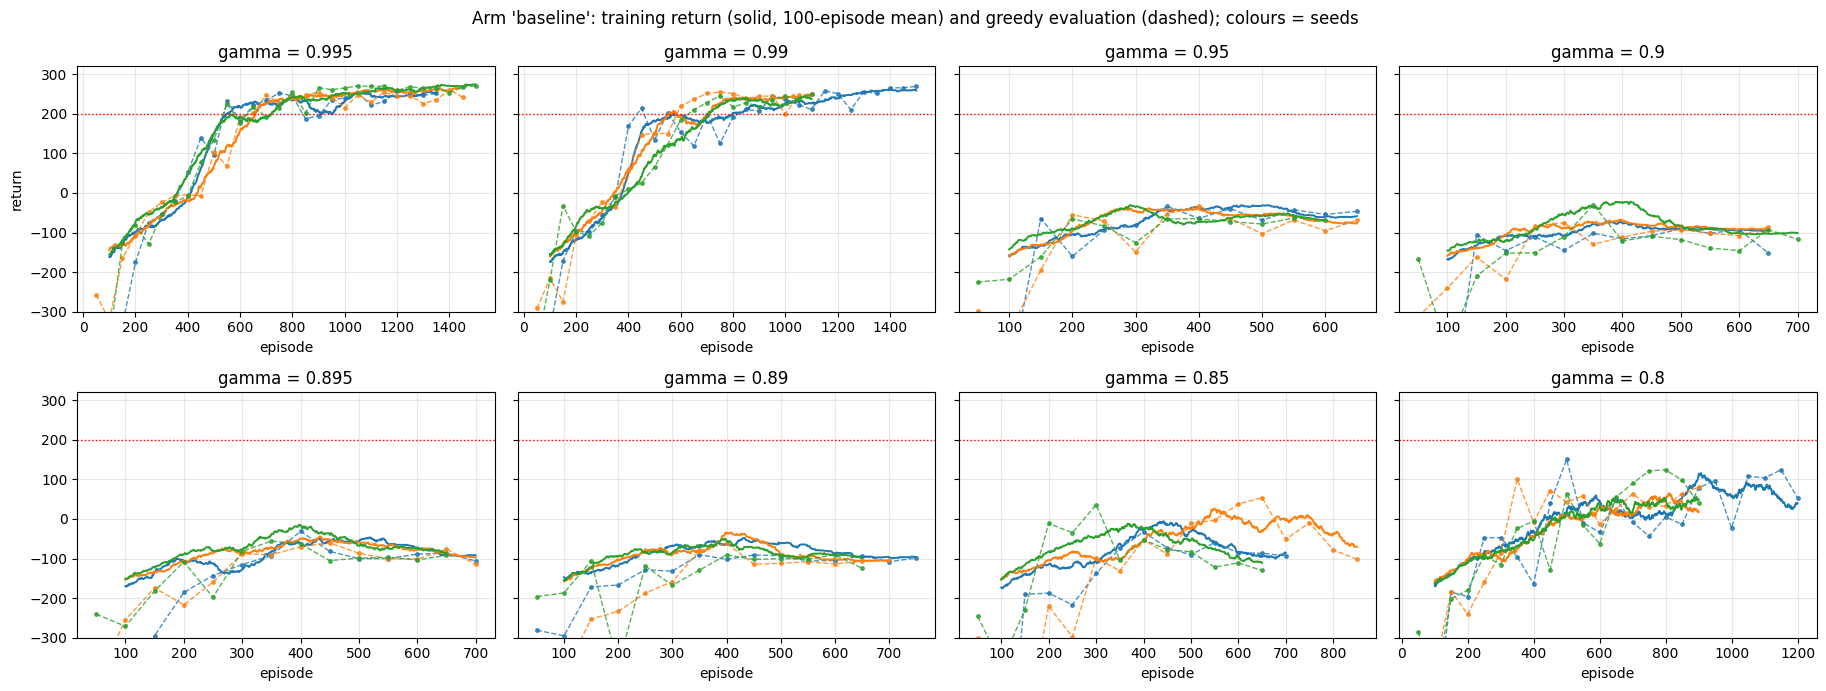

In [ ]:
def fig_curves(R, arm="baseline", fname="learning_curves.png"):
    gammas = sorted({g for (a, g, s) in R if a == arm}, reverse=True)
    if not gammas:
        print("no runs for arm", arm); return
    ncols = 4; nrows = math.ceil(len(gammas) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.5 * nrows), sharey=True, squeeze=False)
    for ax, g in zip(axes.ravel(), gammas):
        for s in CONFIG["seeds"]:
            d = R.get((arm, g, s))
            if d is None:
                continue
            ax.plot(np.arange(1, len(d["ep_reward"]) + 1), rolling_mean(d["ep_reward"]), color=f"C{s}", lw=1.4)
            ax.plot(d["ev_ep"], d["ev_reward"].mean(axis=1), color=f"C{s}", lw=1.0, ls="--", marker="o", ms=2.5, alpha=0.8)
        ax.axhline(200, color="red", ls=":", lw=1); ax.set_title(f"gamma = {g:g}"); ax.grid(alpha=0.3); ax.set_xlabel("episode")
    for ax in axes.ravel()[len(gammas):]:
        ax.axis("off")
    axes[0, 0].set_ylabel("return"); axes[0, 0].set_ylim(-300, 320)
    fig.suptitle(f"Arm '{arm}': training return (solid, 100-episode mean) and greedy evaluation (dashed); colours = seeds")
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=130); plt.show()

fig_curves(RUNS, "baseline", "learning_curves.png")

### 7.2 What the agents do at the end: termination reasons, engine use, altitude (H2)

Final 100-episode greedy evaluation. `time_limit_air` = the episode hit 1000 steps with no leg touching (hovering or flying around); `time_limit_ground` = 1000 steps with a leg touching (resting or bouncing without ever settling).

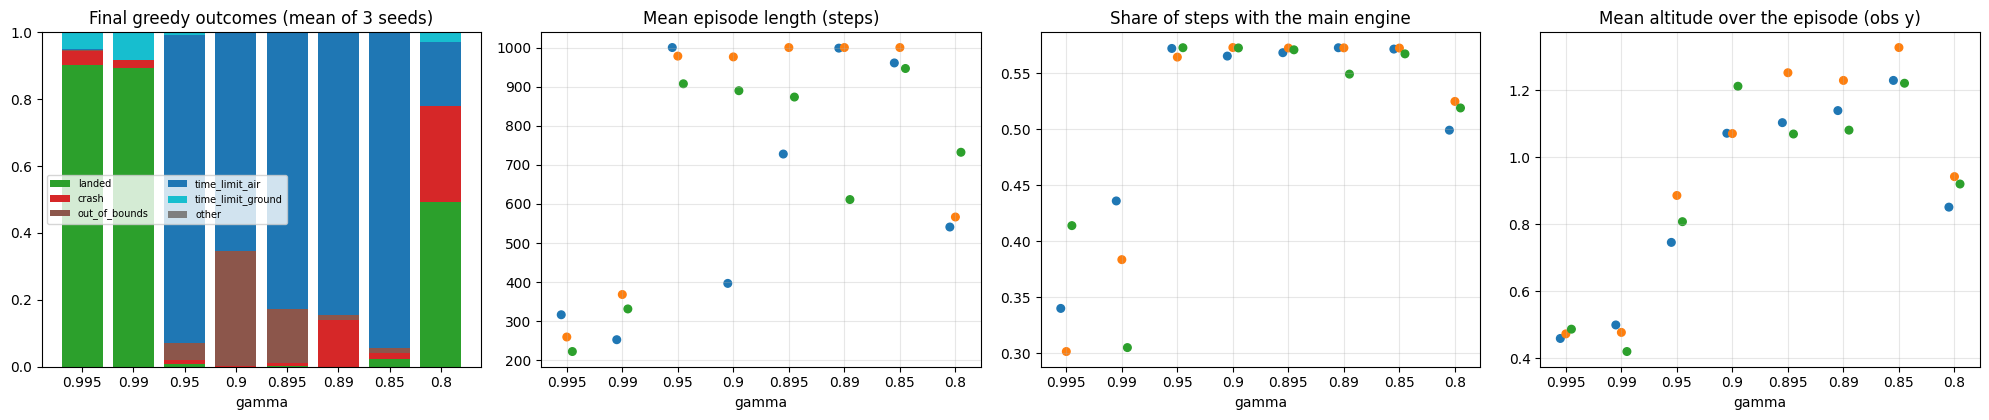

,gamma,seed,solved,n_episodes,final_eval_mean,final_len_mean,share_landed,share_crash,share_out_of_bounds,share_time_limit_air,share_time_limit_ground,final_main_share,final_mean_y
0,1.00,0,True,1350,255.32,316.61,0.91,0.00,0.00,0.00,0.09,0.34,0.46
1,1.00,1,True,1450,236.56,259.68,0.83,0.11,0.00,0.01,0.05,0.30,0.47
2,1.00,2,True,1500,266.85,222.57,0.97,0.01,0.01,0.00,0.01,0.41,0.49
3,0.99,0,True,1500,250.38,252.79,0.91,0.06,0.00,0.00,0.03,0.44,0.50
4,0.99,1,True,1100,241.60,368.38,0.89,0.00,0.00,0.00,0.11,0.38,0.48
5,0.99,2,True,1100,242.70,331.49,0.88,0.01,0.00,0.00,0.11,0.31,0.42
6,0.95,0,False,650,-42.60,1000.00,0.00,0.00,0.00,1.00,0.00,0.57,0.75
7,0.95,1,False,650,-52.22,978.05,0.02,0.02,0.02,0.92,0.02,0.56,0.89
8,0.95,2,False,600,-71.05,907.29,0.00,0.02,0.13,0.85,0.00,0.57,0.81
9,0.90,0,False,650,-143.48,396.81,0.00,0.00,0.80,0.20,0.00,0.57,1.07


In [ ]:
def fig_outcomes(S, fname="outcomes_by_gamma.png"):
    b = S[S.arm == "baseline"]
    if b.empty:
        return
    g_order = sorted(b.gamma.unique(), reverse=True)
    cols = {"landed": "tab:green", "crash": "tab:red", "out_of_bounds": "tab:brown", "time_limit_air": "tab:blue",
            "time_limit_ground": "tab:cyan", "other": "tab:gray"}
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
    bottom = np.zeros(len(g_order))
    for nm in OUT_NAMES:
        v = np.array([b[b.gamma == g][f"share_{nm}"].mean() for g in g_order])
        axes[0].bar(range(len(g_order)), v, bottom=bottom, color=cols[nm], label=nm); bottom += v
    axes[0].set_xticks(range(len(g_order))); axes[0].set_xticklabels([f"{g:g}" for g in g_order]); axes[0].set_title("Final greedy outcomes (mean of 3 seeds)")
    axes[0].set_xlabel("gamma"); axes[0].legend(fontsize=7, ncol=2)
    for ax, col, ttl in ((axes[1], "final_len_mean", "Mean episode length (steps)"), (axes[2], "final_main_share", "Share of steps with the main engine"),
                         (axes[3], "final_mean_y", "Mean altitude over the episode (obs y)")):
        for i, g in enumerate(g_order):
            ax.scatter(np.full(3, i) + np.linspace(-0.1, 0.1, 3), b[b.gamma == g][col], color=[f"C{s}" for s in b[b.gamma == g].seed], s=30)
        ax.set_xticks(range(len(g_order))); ax.set_xticklabels([f"{g:g}" for g in g_order]); ax.set_title(ttl); ax.set_xlabel("gamma"); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=130); plt.show()

fig_outcomes(summary)
cols_show = ["gamma", "seed", "solved", "n_episodes", "final_eval_mean", "final_len_mean", "share_landed", "share_crash", "share_out_of_bounds",
             "share_time_limit_air", "share_time_limit_ground", "final_main_share", "final_mean_y"]
display(base[cols_show].round(2))

### 7.3 Decision rules for H1 and H2

In [ ]:
HOVER_SET = [0.95, 0.9, 0.895, 0.89]


def eval_h1(S):
    b = S[S.arm == "baseline"]
    counts = b.groupby("gamma").solved.sum().to_dict()
    n = b.groupby("gamma").size().to_dict()
    if not counts:
        return "not testable (no baseline runs)", {}
    hi = all(counts.get(g, 0) == n.get(g, 0) == len(CONFIG["seeds"]) for g in (0.995, 0.99))
    lo = all(counts.get(g, 0) == 0 for g in counts if g <= 0.95)
    complete = all(n.get(g, 0) == len(CONFIG["seeds"]) for g in CONFIG["gammas"])
    verdict = ("replicated" if hi and lo else "NOT replicated") + ("" if complete else " (baseline incomplete)")
    return verdict, {g: f"{int(counts[g])}/{n[g]}" for g in sorted(counts, reverse=True)}


def eval_h2(S):
    b = S[S.arm == "baseline"]
    if b.empty:
        return "not testable (no baseline runs)", {}
    per_gamma = {g: int((grp.time_limit_share >= 0.5).sum()) for g, grp in b.groupby("gamma")}
    hover_ok = all(per_gamma.get(g, 0) >= 2 for g in HOVER_SET)
    solved_share = b[b.solved].time_limit_share
    solved_ok = (solved_share.median() < 0.1) if len(solved_share) else False
    air = b[b.time_limit_share > 0].groupby("gamma").apply(lambda x: float(x.share_time_limit_air.sum() / max(x.time_limit_share.sum(), 1e-9)))
    verdict = "supported" if (hover_ok and solved_ok) else "NOT supported"
    return verdict, {"seeds with time_limit_share>=0.5": per_gamma, "median share in solved runs": round(float(solved_share.median()), 3) if len(solved_share) else None,
                     "airborne fraction of time-limit endings": {g: round(v, 2) for g, v in air.items()}}


v1, d1 = eval_h1(summary); v2, d2 = eval_h2(summary)
print("H1 (gamma threshold replicated):", v1, "| solved seeds per gamma:", d1)
print("H2 (failing runs end at the time limit):", v2)
for k, v in d2.items():
    print("   ", k, ":", v)

H1 (gamma threshold replicated): replicated | solved seeds per gamma: {0.995: '3/3', 0.99: '3/3', 0.95: '0/3', 0.9: '0/3', 0.895: '0/3', 0.89: '0/3', 0.85: '0/3', 0.8: '0/3'}
H2 (failing runs end at the time limit): supported
    seeds with time_limit_share>=0.5 : {0.8: 0, 0.85: 3, 0.89: 3, 0.895: 3, 0.9: 2, 0.95: 3, 0.99: 0, 0.995: 0}
    median share in solved runs : 0.075
    airborne fraction of time-limit endings : {0.8: 0.86, 0.85: 1.0, 0.89: 1.0, 0.895: 1.0, 0.9: 1.0, 0.95: 0.99, 0.99: 0.0, 0.995: 0.06}


/tmp/ipykernel_5138/1215687605.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  air = b[b.time_limit_share > 0].groupby("gamma").apply(lambda x: float(x.share_time_limit_air.sum() / max(x.time_limit_share.sum(), 1e-9)))


### 7.4 Decline after the peak, exploration masking, post-solve behaviour (H3, H4, H5)

The peak is located on the training curve; the decline is measured on the independent greedy evaluations (mean of the 3 evaluations around the peak minus the mean of the last 3 evaluations). Each run is one unit.

In [ ]:
def eval_means(d):
    return d["ev_reward"].mean(axis=1)


def greedy_decline(d, k=3):
    m = eval_means(d)
    if len(m) < k + 1:
        return np.nan
    j = int(np.argmin(np.abs(d["ev_ep"] - peak_episode(d))))
    lo = min(max(0, j - 1), len(m) - k)
    return float(m[lo:lo + k].mean() - m[-k:].mean())


def post_solve_decline(d, k=3):
    if d["solved_at"] <= 0:
        return np.nan
    idx = np.where(d["ev_ep"] >= d["solved_at"])[0]
    if len(idx) < 2 * k:
        return np.nan
    m = eval_means(d)
    return float(m[idx[:k]].mean() - m[-k:].mean())


def train_greedy_gap(d):
    """Training 100-episode mean minus greedy mean, at each evaluation episode >= 100."""
    roll = rolling_mean(d["ep_reward"])
    ok = d["ev_ep"] >= 100
    ep = d["ev_ep"][ok]
    return ep, roll[ep - 1] - eval_means(d)[ok]


decline_rows = []
for (arm, g, s), d in sorted(RUNS.items()):
    if arm != "baseline":
        continue
    ep, gap = train_greedy_gap(d)
    j = int(np.argmin(np.abs(ep - peak_episode(d)))) if len(ep) else None
    decline_rows.append(dict(gamma=g, seed=s, solved=d["solved_at"] > 0, peak_ep=peak_episode(d), n_episodes=len(d["ep_reward"]),
                             greedy_decline=greedy_decline(d), post_solve_decline=post_solve_decline(d),
                             gap_at_peak=float(gap[j]) if j is not None else np.nan, gap_at_end=float(gap[-1]) if len(gap) else np.nan,
                             eps_at_peak=float(d["ep_eps"][peak_episode(d) - 1])))
decline_df = pd.DataFrame(decline_rows)
if not decline_df.empty:
    decline_df = decline_df.sort_values(["gamma", "seed"], ascending=[False, True]).reset_index(drop=True)
    decline_df.to_csv(ROOT / "decline_per_run.csv", index=False)
    display(decline_df.round(2))

,gamma,seed,solved,peak_ep,n_episodes,greedy_decline,post_solve_decline,gap_at_peak,gap_at_end,eps_at_peak
0,1.00,0,True,1049,1350,-11.68,-37.74,3.30,-0.75,0.01
1,1.00,1,True,1435,1450,0.00,-7.23,23.45,23.45,0.01
2,1.00,2,True,1499,1500,0.00,-39.63,4.02,4.02,0.01
3,0.99,0,True,1499,1500,0.00,-110.12,-10.61,-10.61,0.01
4,0.99,1,True,1097,1100,0.00,3.46,-1.20,-1.20,0.01
5,0.99,2,True,1073,1100,0.00,-13.63,-0.14,-13.91,0.01
6,0.95,0,False,469,650,-9.84,NaN,3.41,-12.21,0.10
7,0.95,1,False,321,650,-12.87,NaN,102.21,-7.80,0.20
8,0.95,2,False,291,600,-21.53,NaN,89.49,-1.50,0.23
9,0.90,0,False,373,650,-5.42,NaN,25.29,56.44,0.15


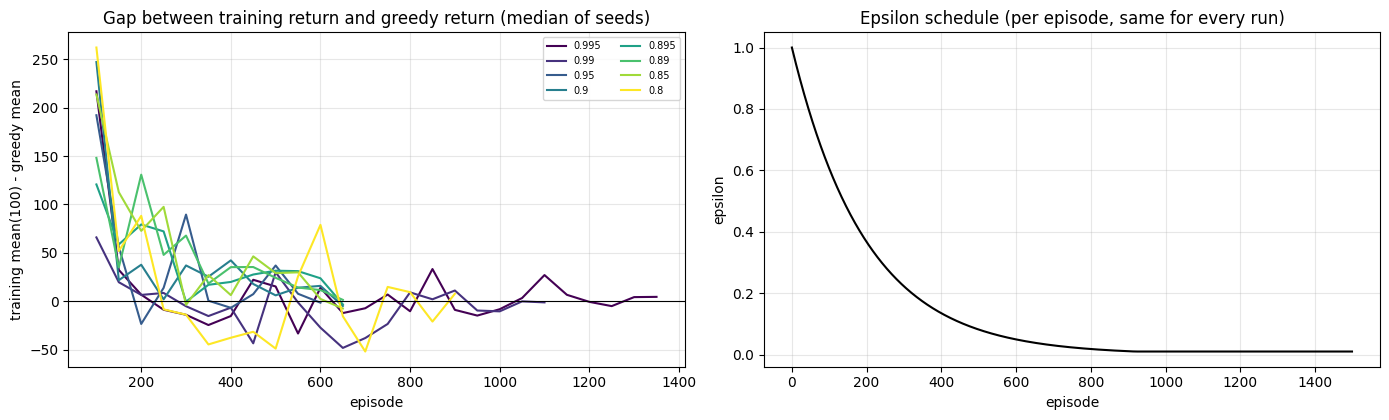

In [ ]:
def fig_gap(R, fname="train_vs_greedy_gap.png"):
    gammas = sorted({g for (a, g, s) in R if a == "baseline"}, reverse=True)
    if not gammas:
        return
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
    for i, g in enumerate(gammas):
        c = plt.cm.viridis(i / max(len(gammas) - 1, 1))
        gaps = [train_greedy_gap(R[("baseline", g, s)]) for s in CONFIG["seeds"] if ("baseline", g, s) in R]
        L = min(len(x[0]) for x in gaps)
        axes[0].plot(gaps[0][0][:L], np.median([x[1][:L] for x in gaps], axis=0), color=c, label=f"{g:g}")
        eps = [R[("baseline", g, s)]["ep_eps"] for s in CONFIG["seeds"] if ("baseline", g, s) in R]
    axes[0].axhline(0, color="k", lw=0.8); axes[0].set_xlabel("episode"); axes[0].set_ylabel("training mean(100) - greedy mean")
    axes[0].set_title("Gap between training return and greedy return (median of seeds)"); axes[0].legend(fontsize=7, ncol=2); axes[0].grid(alpha=0.3)
    e = np.arange(0, 1500); axes[1].plot(e, np.maximum(CONFIG["eps_min"], CONFIG["eps_start"] * CONFIG["eps_decay"] ** e), color="k")
    axes[1].set_xlabel("episode"); axes[1].set_ylabel("epsilon"); axes[1].set_title("Epsilon schedule (per episode, same for every run)"); axes[1].grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=130); plt.show()

fig_gap(RUNS)

### 7.5 Replay buffer, Q values, and the reward-horizon arithmetic (H6 and H9 descriptive parts, H10)

*Descriptive only (no test):* terminal-transition fraction of the buffer and the mean maximum Q value around the training-return peak and at the end of each baseline run; and the arithmetic of `gamma^length` for the typical landing length measured from solved runs.

In [ ]:
def window_mean(x, end_ep, w=100):
    return float(np.mean(x[max(0, end_ep - w):end_ep]))

desc = []
for (arm, g, s), d in sorted(RUNS.items()):
    if arm != "baseline":
        continue
    pk, n = peak_episode(d), len(d["ep_reward"])
    desc.append(dict(gamma=g, seed=s, solved=d["solved_at"] > 0, term_frac_at_peak=window_mean(d["ep_term_frac"], pk), term_frac_at_end=window_mean(d["ep_term_frac"], n),
                     qmax_at_peak=window_mean(d["ep_qmax"], pk), qmax_at_end=window_mean(d["ep_qmax"], n),
                     loss_at_peak=window_mean(d["ep_loss"], pk), loss_at_end=window_mean(d["ep_loss"], n)))
desc_df = pd.DataFrame(desc)
if not desc_df.empty:
    desc_df = desc_df.sort_values(["gamma", "seed"], ascending=[False, True]).reset_index(drop=True)
    desc_df.to_csv(ROOT / "buffer_and_q_descriptives.csv", index=False)
    display(desc_df.round(3))

land_len = np.concatenate([d["final_length"][d["final_outcome"] == 0] for (a, g, s), d in RUNS.items() if a == "baseline" and d["solved_at"] > 0] or [np.array([])])
if len(land_len):
    L_star = float(np.median(land_len))
    hor = pd.DataFrame({"gamma": CONFIG["gammas"], "effective horizon 1/(1-gamma)": [1 / (1 - g) for g in CONFIG["gammas"]],
                        f"gamma^{L_star:.0f} (weight of the +100 seen from the start of a typical landing)": [g ** L_star for g in CONFIG["gammas"]],
                        f"gamma^{L_star / 2:.0f} (from half-way)": [g ** (L_star / 2) for g in CONFIG["gammas"]]})
    hor.to_csv(ROOT / "horizon_vs_flight.csv", index=False)
    print(f"Typical landing length in solved runs (median of landed final-evaluation episodes): {L_star:.0f} steps  [measured]")
    display(hor.round(6))
else:
    print("No landed episodes in solved baseline runs yet; the horizon table needs them.")

,gamma,seed,solved,term_frac_at_peak,term_frac_at_end,qmax_at_peak,qmax_at_end,loss_at_peak,loss_at_end
0,0.995,0,True,0.003,0.003,52.692,64.571,19.399,11.168
1,0.995,1,True,0.004,0.004,76.509,77.348,9.318,9.008
2,0.995,2,True,0.004,0.004,78.058,78.097,6.744,6.756
3,0.990,0,True,0.003,0.003,56.105,56.141,6.186,6.178
4,0.990,1,True,0.003,0.003,40.906,41.061,9.133,9.078
5,0.990,2,True,0.003,0.003,43.760,44.984,16.276,15.160
6,0.950,0,False,0.000,0.000,3.278,0.163,1.874,1.123
7,0.950,1,False,0.002,0.000,1.951,0.252,10.965,2.215
8,0.950,2,False,0.004,0.000,1.420,0.486,14.176,1.147
9,0.900,0,False,0.001,0.000,1.717,-0.592,6.343,0.759


Typical landing length in solved runs (median of landed final-evaluation episodes): 222 steps  [measured]


,gamma,effective horizon 1/(1-gamma),gamma^222 (weight of the +100 seen from the start of a typical landing),gamma^111 (from half-way)
0,0.995,200.000000,0.328643,0.573274
1,0.990,100.000000,0.107402,0.327723
2,0.950,20.000000,0.000011,0.003368
3,0.900,10.000000,0.000000,0.000008
4,0.895,9.523810,0.000000,0.000004
5,0.890,9.090909,0.000000,0.000002
6,0.850,6.666667,0.000000,0.000000
7,0.800,5.000000,0.000000,0.000000


### 7.6 Intervention arms versus the baseline, and the Holm-corrected test family (H3, H5-H9)

Paired differences are (arm - baseline) for the same gamma and seed. The failing-regime test set is gamma in {0.95, 0.9, 0.8}; gamma = 0.99 is a control reported separately. A claim of an effect requires Holm-adjusted p < 0.05, the right direction, **and** an effect larger than the typical seed spread of the baseline.

In [ ]:
UNSOLVED_TEST_GAMMAS = [0.95, 0.9, 0.8]
CONTROL_GAMMA = 0.99


def signflip_test(d, alternative="greater", max_exact=18, n_mc=200_000, seed=0):
    d = np.asarray(d, float); d = d[~np.isnan(d)]; n = len(d)
    if n == 0:
        return np.nan, np.nan, 0
    obs = float(d.mean())
    if n <= max_exact:
        signs = (((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1) * 2 - 1).astype(float); exact = True
    else:
        signs = np.random.default_rng(seed).choice([1.0, -1.0], size=(n_mc, n)); exact = False
    stats = (signs * d).mean(axis=1); tol = 1e-12
    cnt = {"greater": (stats >= obs - tol), "less": (stats <= obs + tol), "two-sided": (np.abs(stats) >= abs(obs) - tol)}[alternative].sum()
    return obs, float(cnt / len(stats) if exact else (cnt + 1) / (len(stats) + 1)), n


def bootstrap_ci(d, n_boot=10_000, seed=0):
    d = np.asarray(d, float); d = d[~np.isnan(d)]
    if len(d) == 0:
        return np.nan, np.nan
    m = np.random.default_rng(seed).choice(d, size=(n_boot, len(d))).mean(axis=1)
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))


def holm_adjust(p):
    p = np.asarray(p, float); adj = np.full_like(p, np.nan)
    valid = np.where(~np.isnan(p))[0]; order = valid[np.argsort(p[valid])]; run, m = 0.0, len(valid)
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def seed_spread(R, fn, gammas):
    sds = []
    for g in gammas:
        v = [fn(R[("baseline", g, s)]) for s in CONFIG["seeds"] if ("baseline", g, s) in R]
        if len(v) >= 2:
            sds.append(np.std(v, ddof=1))
    return float(np.median(sds)) if sds else np.nan


def paired_diffs(R, arm, fn, gammas):
    return [fn(R[(arm, g, s)]) - fn(R[("baseline", g, s)]) for g in gammas for s in CONFIG["seeds"] if (arm, g, s) in R and ("baseline", g, s) in R]


final_mean = lambda d: float(d["final_reward"].mean())
tl_share = lambda d: float(np.mean((d["final_outcome"] == 3) | (d["final_outcome"] == 4)))


def make_row(hid, claim, vals, alternative, spread):
    est, p, n = signflip_test(vals, alternative)
    lo, hi = bootstrap_ci(vals)
    return dict(id=hid, claim=claim, alternative=alternative, n_units=n, estimate=est, ci95_low=lo, ci95_high=hi, seed_spread=spread, p_raw=p)


# ---- unit tests of the statistics helpers (cheap; they run every time the analysis runs) ----
_o, _p, _n = signflip_test([1, 1, 1, 1], "greater"); assert abs(_p - 1 / 16) < 1e-12 and _n == 4
assert abs(signflip_test([1, 1, 1, 1], "two-sided")[1] - 2 / 16) < 1e-12
assert abs(signflip_test([1, -1, 1, -1], "greater")[1] - 11 / 16) < 1e-12
assert np.allclose(holm_adjust([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06]) and np.isnan(holm_adjust([np.nan, 0.01])[0])
_synth = {"ep_reward": np.concatenate([np.linspace(-150, 0, 300), np.linspace(0, -120, 300)]), "ev_ep": np.arange(50, 601, 50),
          "solved_at": 150}
_synth["ev_reward"] = np.array([[v, v] for v in np.concatenate([np.linspace(-140, 0, 6), np.linspace(-10, -110, 6)])])
assert greedy_decline(_synth) > 50 and post_solve_decline(_synth) > 0
assert np.isnan(post_solve_decline(dict(_synth, solved_at=-1)))
print("statistics helpers: unit tests passed")


def run_family(R):
    rows = []
    unsolved = [d for (a, g, s), d in R.items() if a == "baseline" and d["solved_at"] <= 0]
    solved = [d for (a, g, s), d in R.items() if a == "baseline" and d["solved_at"] > 0]
    ug = sorted({float(d["gamma"]) for d in unsolved}); sg = sorted({float(d["gamma"]) for d in solved})
    rows.append(make_row("H3", "greedy return decline after the training-return peak, unsolved baseline runs", [greedy_decline(d) for d in unsolved], "greater", seed_spread(R, greedy_decline, ug)))
    rows.append(make_row("H5", "greedy return decline after solving, solved baseline runs", [post_solve_decline(d) for d in solved], "greater", seed_spread(R, post_solve_decline, sg)))
    for hid, arm, text, fn, alt in (("H6", "big_buffer", "buffer 1M vs 100k: change in final greedy return", final_mean, "greater"),
                                    ("H7", "shaping_fix", "gamma-consistent shaping: change in final greedy return", final_mean, "greater"),
                                    ("H8", "trunc_terminal", "time limit as terminal: change in time-limit share", tl_share, "two-sided"),
                                    ("H9", "huber", "Huber loss: change in final greedy return", final_mean, "greater")):
        rows.append(make_row(hid, text, paired_diffs(R, arm, fn, UNSOLVED_TEST_GAMMAS), alt, seed_spread(R, fn, UNSOLVED_TEST_GAMMAS)))
    df = pd.DataFrame(rows)
    df["p_holm"] = holm_adjust(df.p_raw.values)

    def verdict(r):
        if np.isnan(r.p_holm):
            return "not testable (missing runs)"
        right = (r.estimate > 0) if r.alternative == "greater" else True
        if r.p_holm < 0.05 and right and abs(r.estimate) > r.seed_spread:
            return "supported" + ("" if r.alternative == "greater" else (" (arm increases it)" if r.estimate > 0 else " (arm decreases it)"))
        if r.p_holm < 0.05 and right:
            return "significant but not larger than seed spread: not claimed"
        return "not supported at this sample size"
    df["verdict"] = df.apply(verdict, axis=1)
    return df


tests = run_family(RUNS)
tests_out = pd.concat([tests, pd.DataFrame([dict(id="H1", claim="gamma threshold replicated", verdict=v1), dict(id="H2", claim="failing runs end at the time limit", verdict=v2)])], ignore_index=True)
tests_out.to_csv(ROOT / "hypothesis_tests.csv", index=False)
display(tests.round(4))

# H4: decided from H3 and the gap curves, no separate test
h3 = tests[tests.id == "H3"].iloc[0]
if decline_df.empty or np.isnan(h3.p_holm):
    print("H4: not decidable yet (missing baseline runs).")
else:
    u = decline_df[~decline_df.solved]
    print(f"H4 evidence [measured]: unsolved runs, training-minus-greedy gap at the peak {u.gap_at_peak.mean():.1f} vs at the end {u.gap_at_end.mean():.1f} "
          f"(mean over runs); mean greedy decline {u.greedy_decline.mean():.1f}.")
    print("H4 rule:", "H3 is supported -> the greedy policy itself got worse; masking by epsilon decay can at most be a contributor."
          if h3.verdict.startswith("supported") else "H3 is not supported -> if training return still falls, the data fit masking better than degradation (check the gap curves).")

# control: gamma = 0.99 (do no harm), descriptive
ctrl = []
for arm in INTERVENTION_ARMS:
    for fn_name, fn in (("final_eval_mean", final_mean), ("time_limit_share", tl_share)):
        v = paired_diffs(RUNS, arm, fn, [CONTROL_GAMMA])
        if v:
            ctrl.append(dict(arm=arm, metric=fn_name, gamma=CONTROL_GAMMA, mean_diff_vs_baseline=float(np.mean(v)), n_pairs=len(v), diffs=[round(x, 2) for x in v]))
print("Control (gamma = 0.99), arm minus baseline, descriptive only:")
display(pd.DataFrame(ctrl))

statistics helpers: unit tests passed


,id,claim,alternative,n_units,estimate,ci95_low,ci95_high,seed_spread,p_raw,p_holm,verdict
0,H3,greedy return decline after the training-retur...,greater,18,8.9039,-4.1447,23.3107,16.9122,0.1243,0.7458,not supported at this sample size
1,H5,"greedy return decline after solving, solved ba...",greater,6,-34.1496,-67.3812,-8.7514,39.7141,0.9844,1.0000,not supported at this sample size
2,H6,buffer 1M vs 100k: change in final greedy return,greater,9,-2.7231,-33.3870,27.8410,14.4736,0.5762,1.0000,not supported at this sample size
3,H7,gamma-consistent shaping: change in final gree...,greater,9,-222.3832,-353.6710,-101.6493,14.4736,0.9961,1.0000,not supported at this sample size
4,H8,time limit as terminal: change in time-limit s...,two-sided,9,0.0533,-0.0856,0.2178,0.1153,0.5391,1.0000,not supported at this sample size
5,H9,Huber loss: change in final greedy return,greater,9,-1.1931,-22.3196,16.4300,14.4736,0.5410,1.0000,not supported at this sample size


H4 evidence [measured]: unsolved runs, training-minus-greedy gap at the peak 43.4 vs at the end 5.6 (mean over runs); mean greedy decline 8.9.
H4 rule: H3 is not supported -> if training return still falls, the data fit masking better than degradation (check the gap curves).
Control (gamma = 0.99), arm minus baseline, descriptive only:


,arm,metric,gamma,mean_diff_vs_baseline,n_pairs,diffs
0,shaping_fix,final_eval_mean,0.99,-40.202408,3,"[-42.85, -27.73, -50.02]"
1,shaping_fix,time_limit_share,0.99,0.013333,3,"[0.09, -0.06, 0.01]"
2,big_buffer,final_eval_mean,0.99,-65.293484,3,"[-60.35, -92.09, -43.44]"
3,big_buffer,time_limit_share,0.99,0.043333,3,"[0.1, 0.0, 0.03]"
4,trunc_terminal,final_eval_mean,0.99,-7.436884,3,"[2.35, -29.28, 4.63]"
5,trunc_terminal,time_limit_share,0.99,0.006667,3,"[0.02, 0.01, -0.01]"
6,huber,final_eval_mean,0.99,-42.161067,3,"[-59.0, -33.28, -34.21]"
7,huber,time_limit_share,0.99,0.293333,3,"[0.53, 0.27, 0.08]"


In [ ]:
def fig_arms(S, fname="arms_vs_baseline.png"):
    arms = [a for a in INTERVENTION_ARMS if (S.arm == a).any()]
    if not arms:
        print("no intervention runs finished yet"); return
    gam = sorted(S[S.arm == "baseline"].gamma.unique(), reverse=True)
    gam = [g for g in gam if g in INTERVENTION_GAMMAS]
    fig, axes = plt.subplots(1, len(arms), figsize=(5.2 * len(arms), 4.2), sharey=True, squeeze=False)
    for ax, arm in zip(axes[0], arms):
        for i, g in enumerate(gam):
            for k, (a, col, off) in enumerate((("baseline", "tab:gray", -0.12), (arm, "tab:orange", 0.12))):
                v = S[(S.arm == a) & (S.gamma == g)].final_eval_mean
                ax.scatter(np.full(len(v), i) + off, v, color=col, s=34, label=a if i == 0 else None)
        ax.axhline(200, color="red", ls=":", lw=1); ax.set_xticks(range(len(gam))); ax.set_xticklabels([f"{g:g}" for g in gam])
        ax.set_title(arm); ax.set_xlabel("gamma"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    axes[0, 0].set_ylabel("final greedy return (100 episodes), one dot per seed")
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=130); plt.show()

fig_arms(summary)

In [ ]:
def fig_post_solve(R, fname="post_solve.png"):
    runs = [(g, s, d) for (a, g, s), d in sorted(R.items()) if a == "baseline" and d["solved_at"] > 0]
    if not runs:
        print("no solved baseline runs yet"); return
    fig, ax = plt.subplots(figsize=(8, 4.3))
    for g, s, d in runs:
        ax.plot(d["ev_ep"] - d["solved_at"], eval_means(d), color=plt.cm.viridis(0.1 if g == 0.995 else 0.6), alpha=0.8, label=f"gamma {g:g}" if s == 0 else None)
    ax.axvline(0, color="k", lw=0.8); ax.axhline(200, color="red", ls=":", lw=1)
    ax.set_xlabel("episodes relative to the first time the 100-episode training mean reached 200"); ax.set_ylabel("greedy evaluation return")
    ax.set_title("Solved runs after solving (H5)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=130); plt.show()

fig_post_solve(RUNS)

## 8. Videos

Videos show greedy rollouts of saved policies so the behaviour can be seen, not only measured. **Selection rule, fixed in advance:** seed 0 of each (arm, gamma), and the first held-out evaluation initial condition (`EVAL_SEEDS_PERIODIC[0]`) for every panel. These are illustrations of single runs, not evidence; the evidence is in Section 7.

Files (Drive: `dqn_lunar/03_diagnostics/videos/`, repo: `results/03_diagnostics/videos/`):

- `overview_final_policies.mp4` / `.gif`: the final policy of all 8 baseline gammas side by side (same initial condition).
- `peak_vs_final_gamma<g>.mp4`: for each failing gamma, the policy near the training-return peak (left) and the final policy (right).
- `arms_gamma<g>.mp4`: the baseline and each intervention arm at one gamma (same initial condition).

Playback is real time (25 frames per second, every second simulation frame). Panels freeze on their last frame, with the outcome and return, until the longest panel finishes. In the repo, the GIF renders inline in a README and the MP4 opens in GitHub's player.

In [ ]:
VIDEO_SEED = 0
VIDEO_ENV_SEED = EVAL_SEEDS_PERIODIC[0]
PANEL_SIZE = (300, 200)
OUT_COLOURS = {0: (80, 220, 90), 1: (255, 90, 90), 2: (255, 150, 60), 3: (110, 170, 255), 4: (90, 220, 230), 5: (200, 200, 200)}


def _font(size=13):
    from PIL import ImageFont
    try:
        return ImageFont.load_default(size=size)
    except TypeError:
        return ImageFont.load_default()


def get_policy(R, arm, gamma, seed, which):
    with np.load(SNAP_DIR / f"{run_name(arm, gamma, seed)}.npz") as z:
        eps, W, sizes = z["ep"], z["w"], tuple(int(x) for x in z["sizes"])
    k = len(eps) - 1 if which == "final" else int(np.argmin(np.abs(eps - peak_episode(R[(arm, gamma, seed)]))))
    return unflatten_weights(W[k], sizes), int(eps[k])


def rollout_frames(params, cfg, env_seed, stride=2, size=PANEL_SIZE):
    from PIL import Image
    env = make_env(cfg, render=True)
    s, _ = env.reset(seed=int(env_seed))
    frames, meta, total, step = [], [], 0.0, 0
    while True:
        if step % stride == 0:
            frames.append(np.asarray(Image.fromarray(env.render()).resize(size, Image.BILINEAR)))
            meta.append((step, total))
        s, r, term, trunc, _ = env.step(int(np.argmax(forward(params, s))))
        total += r; step += 1
        if term or trunc:
            break
    frames.append(np.asarray(Image.fromarray(env.render()).resize(size, Image.BILINEAR))); meta.append((step, total))
    env.close()
    return {"frames": frames, "meta": meta, "outcome": classify_outcome(r, term, trunc, s), "total": total, "steps": step}


def write_grid_video(panels, path, ncols, fps=25, hold_seconds=1.0, gif_path=None, gif_stride=4, gif_width=640):
    import imageio
    from PIL import Image, ImageDraw
    w, h = PANEL_SIZE
    nrows = math.ceil(len(panels) / ncols)
    n_frames = max(len(p["rollout"]["frames"]) for p in panels) + int(hold_seconds * fps)
    font = _font(13)
    writer = imageio.get_writer(str(path), fps=fps, codec="libx264", pixelformat="yuv420p", macro_block_size=1, quality=7)
    gif_frames = []
    for t in range(n_frames):
        canvas = np.zeros((nrows * h, ncols * w, 3), np.uint8)
        for i, p in enumerate(panels):
            ro = p["rollout"]; last = len(ro["frames"]) - 1; k = min(t, last)
            img = Image.fromarray(ro["frames"][k]); dr = ImageDraw.Draw(img)
            dr.rectangle([0, 0, w, 33], fill=(0, 0, 0)); dr.text((4, 1), p["title"], font=font, fill=(255, 255, 255))
            if t >= last:
                dr.text((4, 17), f"{OUT_NAMES[ro['outcome']].upper()}  return {ro['total']:.0f}  ({ro['steps']} steps)", font=font, fill=OUT_COLOURS[ro["outcome"]])
            else:
                dr.text((4, 17), f"t={ro['meta'][k][0]}  return {ro['meta'][k][1]:.0f}", font=font, fill=(200, 200, 200))
            r0, c0 = (i // ncols) * h, (i % ncols) * w
            canvas[r0:r0 + h, c0:c0 + w] = np.asarray(img)
        writer.append_data(canvas)
        if gif_path is not None and t % gif_stride == 0:
            im = Image.fromarray(canvas)
            gif_frames.append(im.resize((gif_width, int(canvas.shape[0] * gif_width / canvas.shape[1])), Image.BILINEAR))
    writer.close()
    if gif_path is not None and gif_frames:
        gif_frames[0].save(str(gif_path), save_all=True, append_images=gif_frames[1:], duration=int(1000 * gif_stride / fps), loop=0, optimize=True)


def render_all_videos(R, overwrite=False):
    written = []
    def _skip(path):
        return path.exists() and not overwrite
    base_g = sorted({g for (a, g, s) in R if a == "baseline" and s == VIDEO_SEED}, reverse=True)
    # 1) overview of the final baseline policies
    out = VIDEO_DIR / "overview_final_policies.mp4"
    if base_g and not _skip(out):
        panels = []
        for g in base_g:
            params, ep = get_policy(R, "baseline", g, VIDEO_SEED, "final")
            panels.append({"title": f"gamma={g:g}  final policy (ep {ep})", "rollout": rollout_frames(params, CONFIG, VIDEO_ENV_SEED)})
        write_grid_video(panels, out, ncols=4, gif_path=VIDEO_DIR / "overview_final_policies.gif"); written.append(out)
    # 2) peak vs final for every failing gamma
    for g in base_g:
        d = R[("baseline", g, VIDEO_SEED)]
        out = VIDEO_DIR / f"peak_vs_final_gamma{g:.3f}.mp4"
        if d["solved_at"] > 0 or _skip(out):
            continue
        panels = []
        for which, label in (("peak", "near training peak"), ("final", "final")):
            params, ep = get_policy(R, "baseline", g, VIDEO_SEED, which)
            panels.append({"title": f"gamma={g:g}  {label} (ep {ep})", "rollout": rollout_frames(params, CONFIG, VIDEO_ENV_SEED)})
        write_grid_video(panels, out, ncols=2); written.append(out)
    # 3) baseline vs every finished intervention arm
    for g in INTERVENTION_GAMMAS:
        out = VIDEO_DIR / f"arms_gamma{g:.3f}.mp4"
        arms = [a for a in ["baseline"] + INTERVENTION_ARMS if (a, g, VIDEO_SEED) in R]
        if len(arms) < 2 or _skip(out):
            continue
        panels = []
        for a in arms:
            params, ep = get_policy(R, a, g, VIDEO_SEED, "final")
            panels.append({"title": f"{a}  gamma={g:g}  (ep {ep})", "rollout": rollout_frames(params, CONFIG, VIDEO_ENV_SEED)})
        write_grid_video(panels, out, ncols=3); written.append(out)
    for p in written + [VIDEO_DIR / "overview_final_policies.gif"]:
        if p.exists():
            print(f"{p.name:<40} {p.stat().st_size / 1e6:6.1f} MB")
    return written


_ = render_all_videos(RUNS)         # skips videos that already exist; set overwrite=True to redo

In [ ]:
EMBED_VIDEOS_IN_NOTEBOOK = False     # True embeds the video in this session's output (it also bloats the saved .ipynb)
try:
    from IPython.display import Video, display as _display
except Exception:
    EMBED_VIDEOS_IN_NOTEBOOK = False
for p in sorted(VIDEO_DIR.glob("*.mp4")):
    print(f"{p.name}\n   Drive: {p}\n   GitHub (after publishing): {GITHUB_BLOB}/videos/{p.name}")
    if EMBED_VIDEOS_IN_NOTEBOOK:
        _display(Video(str(p), embed=True, width=900))

**Videos on GitHub** (these links work after the results are published to the repository):

[![Final policies of all 8 gammas](https://github.com/mjsafy/dqn-lunarlander-experiments/raw/main/results/03_diagnostics/videos/overview_final_policies.gif)](https://github.com/mjsafy/dqn-lunarlander-experiments/blob/main/results/03_diagnostics/videos/overview_final_policies.mp4)

Full-quality MP4s: [overview of final policies](https://github.com/mjsafy/dqn-lunarlander-experiments/blob/main/results/03_diagnostics/videos/overview_final_policies.mp4) | `peak_vs_final_gamma<g>.mp4` and `arms_gamma<g>.mp4` in the same folder.

## 9. Results and conclusions

*Numbers are copied from the outputs of Sections 5 and 7 ("measured") unless marked "reasoning". There are 3 seeds per setting; read Section 10 before quoting anything.*

### Validation of the agent (Section 5.2)

At gamma 0.95 and 0.9 the TensorFlow run of Experiment 01 fell inside the NumPy seed range (plus the pre-set margins) for all three compared metrics (6 of 6). Only one TensorFlow run per gamma exists, so this shows no evidence of a difference, not equivalence. At gamma 0.9 the TensorFlow run had shorter episodes over episodes 301-400 (777) than all three NumPy seeds (836-918).

### Hypothesis scorecard

| ID | Verdict | Key numbers (measured) | Caveat |
|---|---|---|---|
| H1 | **replicated** | Solved in 3/3 seeds at 0.995 (median 660 episodes) and 0.99 (median 571); 0/3 at each of the six lower values, including 0.8 | The threshold between 0.95 and 0.99 is still not located |
| H2 | **supported** | Gamma 0.95, 0.895, 0.89, 0.85: 3/3 seeds with at least 50% time-limit endings; gamma 0.9: 2/3 (the third seed ended 80% out of bounds); median share in solved runs 0.075. Time-limit endings were airborne in 99-100% of cases | "Hover" is inferred from altitude, engine use and airborne time-limit endings |
| H3 | not supported | Mean greedy decline after the training-return peak +8.9 (95% CI -4.1 to +23.3; 18 runs), seed spread 16.9, Holm p = 0.75 | A decline of up to about 23 cannot be excluded; the pattern differs between gammas (see below) |
| H4 | consistent with masking as a contributor (descriptive) | Training-minus-greedy gap 43.4 at the peak vs 5.6 at the end (mean over unsolved runs); mean greedy decline 8.9 | The gap at the peak is biased upward because the peak is chosen on the training curve; no separate test |
| H5 | not supported (opposite direction) | Greedy return kept rising after solving: mean change -34.1 (CI -67.4 to -8.8; 6 runs; negative = rising); final greedy returns 237-267 | Followed for 500-900 episodes beyond solving, with epsilon at its floor of 0.01 |
| H6 | not supported | Buffer 1M vs 100k: -2.7 (CI -33.4 to +27.8; 9 pairs). Control gamma 0.99: -65.3 (3/3 pairs negative) | Reasoning: with about 650 episodes of about 950 steps the 1M buffer probably never evicted anything, yet nothing improved |
| H7 | not supported, and harmful | Shaping correction: -222.4 (CI -353.7 to -101.7; 9 pairs). Control gamma 0.99: -40.2 (3/3 pairs negative) | The pre-registered test looked for improvement; reading the harm from the interval is exploratory. The correction is approximate at terminal steps |
| H8 | not supported | Time limit as terminal: time-limit share +0.053 (CI -0.086 to +0.218). Control: +0.007 | |
| H9 | not supported | Huber: -1.2 (CI -22.3 to +16.4). Control gamma 0.99: -42.2 with time-limit share +0.53, +0.27, +0.08 | Huber hurt at the control, one implementation (delta = 1) |
| H10 | descriptive | Typical landing 222 steps. gamma^222: 0.33 (0.995), 0.11 (0.99), 1.1e-5 (0.95), 7e-11 (0.9). From half-way (111 steps): 0.57, 0.33, 0.0034, 8e-6 | Arithmetic only, no test |

### What the agents do (measured)

- **Solved runs (0.995, 0.99):** final greedy return 237-267, 83-97% landed, main engine on 30-44% of steps, mean altitude 0.42-0.50, episodes of 223-368 steps.
- **Failing runs (gamma 0.95 to 0.85, 15 runs):** final greedy return -143 to -43; main engine on 55-57% of steps; mean altitude 0.75-1.33; at most 5% of episodes end in a landing; episodes last 397-1000 steps. Two runs differ: gamma 0.9 seed 0 (80% out of bounds) and gamma 0.89 seed 2 (42% crashes).
- **Gamma 0.8:** final greedy return +29 to +51, 41-55% landed, 17-36% crashed; experiment 01's observation that 0.8 is the best of the unsolved values is reproduced with 3 seeds.
- **Replay buffer and value estimates:** at the end of failing runs the terminal-transition fraction is at most 0.001 (0.003-0.004 in solved runs) and the mean maximum Q is between -0.6 and +1.0 (41-78 in solved runs).
- **Decline by gamma (greedy return around the peak minus the last 3 evaluations, mean over 3 seeds, exploratory):** 0.95: -14.7; 0.9: +4.1; 0.895: +15.8; 0.89: +8.7; 0.85: +58.4; 0.8: -18.8. Only gamma 0.85 is positive in all 3 seeds (+23.0, +71.0, +81.1).

### Which explanations survive (reasoning)

1. **Failing runs settle into one stable behaviour:** flying high with the main engine on for about 57% of the steps and almost never landing. The duty cycle is nearly identical across 15 runs. The failure is not an artefact of the NumPy agent (Section 5.2).
2. **The "rise then fall" of Experiment 01 is mostly a statement about training return under epsilon-greedy noise.** The greedy policy's decline was not detected on average, and the shrinking training-greedy gap accounts for most of the training-return decline (approximate, because the gap at the peak is upward-biased). A real greedy decline is possible at gamma 0.85 (exploratory).
3. **Not explained by:** buffer capacity (H6), treating the time limit as non-terminal (H8), or squared loss on large rewards (H9). Each "not supported" means no detectable effect of that implementation at this sample size, not proof of no effect.
4. **The shaping correction as implemented hurt.** One possible reason (untested): it adds (1 - gamma) * |Phi(s')| to every non-terminal step, which can be of order 10 per step at gamma 0.9, so the value function must represent large state-dependent offsets. This does not show that the original inconsistency plays no role.
5. **Still standing:** a short effective horizon relative to the flight (H10). At gamma 0.95 the landing reward seen from the start of a typical flight is weighted by about 1e-5, and the value estimates of failing runs contain almost no landing or crash signal. This is consistent with the data but was not tested directly, because no arm lengthened the horizon without changing gamma.
6. **Unexplained:** gamma 0.8 lands about half of the time while 0.85-0.95 hover.

### Deviations from the pre-registration (Section 0)

No rule, threshold, gamma set, arm or exclusion of Section 0 was changed after seeing results. Additions made after seeing results, all exploratory: the per-gamma means of the greedy decline (including the gamma 0.85 observation), the two-sided reading of the H7 interval (the pre-registered test was one-sided for improvement), the comparison of gamma 0.8 with its neighbours, and the control-gamma observations (descriptive).

## 10. Limitations (read before quoting any number)

- **Three seeds.** Tests pool runs from at most 3-4 gammas; runs from the same gamma are not fully independent, so p-values are optimistic and gamma-specific claims (such as the gamma 0.85 decline) are exploratory.
- **Data-dependent stopping.** Runs stop at different episodes. The rule uses training returns under epsilon-greedy noise and a naive standard error that ignores autocorrelation. Failing runs stopped between episodes 600 and 1200, solved runs between 1100 and 1500.
- **Peak selection.** The peak is chosen on the training curve, so any quantity measured on the training curve at the peak (such as the gap) is biased upward. The greedy decline avoids this by using independent evaluations, but each evaluation has only 20 episodes and each window averages 3 evaluations.
- **Agent change.** The NumPy agent matches the TensorFlow design but is not bit-identical; it was compared with one TensorFlow run per gamma over 400 episodes. Passing that check does not prove equivalence.
- **One implementation of each intervention.** `shaping_fix` is approximate at terminal steps; `big_buffer` changes capacity only; `huber` uses delta = 1 without gradient clipping or learning-rate decay. "Not supported" means no detectable effect of this implementation at this sample size.
- **Intervention gammas.** The arms use gamma 0.99, 0.95, 0.9 and 0.8 only; the test set for H6-H9 is 0.95, 0.9 and 0.8 (9 pairs), and 0.99 is a descriptive control.
- **Outcome classification** relies on the +-100 terminal-reward convention (checked by the smoke test) and on leg contacts to separate airborne from ground time-limit endings.
- **Epsilon is decayed per episode,** so episode counts at a given gamma are tied to the exploration schedule.
- **Videos** illustrate single runs on one fixed initial condition.

## 11. Next experiments (candidates)

1. **Test the horizon hypothesis directly:** n-step returns (for example n = 10 and 30) at gamma 0.95 and 0.9, which lengthen the effective horizon without changing gamma. If hovering disappears, the horizon explanation gains direct support.
2. **Locate the threshold:** gamma 0.96, 0.97, 0.98 with 3+ seeds; compare the threshold with the arithmetic of H10.
3. **Use the saved snapshots (no new training):** roll out the policy of every 50-episode snapshot for gamma 0.85-0.95 to find when hovering starts and whether the policy near the training peak was already hovering.
4. **Understand gamma 0.8 and 0.85:** more seeds (5-10), trajectories of landing versus non-landing episodes, and longer training for 0.8 (its curves were still rising when stopped).
5. **Understand why the shaping correction hurt:** log Q ranges and outcomes for that arm, then try a normalised potential or the full terminal-consistent potential-based form.
6. Double DQN and dueling networks, and gradient clipping and learning-rate decay separately from the loss, against this baseline.